# Isolation Forest for Outlier Detection
## ICU Telemetry Anomaly Detection

### Learning Objectives
- Understand the theory and intuition behind Isolation Forest
- Learn how to detect anomalies in continuous bedside monitoring data
- Explore the impact of key hyperparameters interactively
- Interpret model decisions and anomaly scores
- Compare with other outlier detection methods

### Use Case: ICU Telemetry Monitoring
We'll analyze continuous vital-sign telemetry from ICU patients to detect anomalies that could indicate:
- Acute physiological deterioration
- Unusual hemodynamic or respiratory states
- Early warning of an adverse event
- Monitor artefacts and lead displacement

> **A note on the data.** Every patient record in this notebook is simulated from
> published physiological reference ranges. No real or identifiable patient data is used.


## 1. Theoretical Foundation

### What is Isolation Forest?

Isolation Forest is an unsupervised learning algorithm specifically designed for **anomaly detection**. Unlike traditional methods that profile normal data and identify outliers as deviations, Isolation Forest explicitly isolates anomalies.

### Key Intuition

**Anomalies are few and different** - they are easier to isolate than normal points.

Imagine you have a bag of apples with one orange:
- To isolate the orange, you might ask: "Is it orange colored?" → Done!
- To isolate a specific apple, you'd need many questions: "Is it red? Is it large? Does it have spots?"

### How It Works

1. **Random Partitioning**: Randomly select a feature and a split value
2. **Tree Construction**: Recursively partition data until points are isolated
3. **Path Length**: Measure the number of splits needed to isolate each point
4. **Anomaly Score**: Points with shorter paths are more likely to be anomalies

### Mathematical Foundation

**Anomaly Score**:
$$s(x, n) = 2^{-\frac{E(h(x))}{c(n)}}$$

Where:
- $E(h(x))$ = Average path length to isolate point $x$
- $c(n)$ = Average path length of unsuccessful search in BST (normalization)
- $n$ = Number of samples

**Interpretation**:
- Score ≈ 1: Definite anomaly
- Score ≈ 0.5: Normal instance
- Score < 0.5: Safe to consider normal

### Visual Example: Isolation Path Length

Below is a conceptual illustration of how Isolation Forest works:

```
Normal Point (Many Splits Required):
├─ Split 1: Temp > 37.0°C?
│  ├─ Split 2: Heart Rate > 80 bpm?
│  │  ├─ Split 3: Resp Rate > 17?
│  │  │  ├─ Split 4: MAP > 86 mmHg?
│  │  │  │  ├─ Split 5: SpO2 > 96%?
│  │  │  │  │  └─ [ISOLATED] ← Path Length = 5

Anomaly (Few Splits Required):
├─ Split 1: SpO2 < 88%?
│  └─ [ISOLATED] ← Path Length = 1
```

**Key Insight**: Anomalies are isolated faster because they're different and far from the dense normal cluster.


In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
import ipywidgets as widgets
from IPython.display import display
import plotly.graph_objects as go
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Random seed for reproducibility
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Generate ICU Telemetry Data

We'll simulate vital-sign readings from a bedside patient monitor:
- **Heart Rate** (beats per minute)
- **Mean Arterial Pressure, MAP** (mmHg)
- **Oxygen Saturation, SpO2** (%)
- **Respiratory Rate** (breaths per minute)
- **Body Temperature** (°C)

Stable patients follow expected patterns, while anomalies represent:
- Acute deterioration episodes
- Unusual physiological states
- Monitor artefacts and displaced leads

All values are simulated from published reference ranges - no real or
identifiable patient data is used.


In [2]:
def generate_icu_telemetry_data(n_samples=1000, n_anomalies=50, random_state=42):
    """
    Generate synthetic ICU bedside-monitor telemetry with anomalies.

    Parameters:
    -----------
    n_samples : int
        Number of normal (stable) samples
    n_anomalies : int
        Number of anomalous samples
    random_state : int
        Random seed for reproducibility

    Returns:
    --------
    X : ndarray
        Feature matrix
    y_true : ndarray
        True labels (1 for normal, -1 for anomaly)
    feature_names : list
        Names of features

    The values are simulated from published physiological reference ranges.
    No real or identifiable patient data is used.
    """
    np.random.seed(random_state)

    # Stable physiology - correlated vital signs.
    # Heart rate is the driver: temperature and respiratory rate track it,
    # and SpO2 falls as respiratory rate climbs.
    heart_rate_normal = np.random.normal(78, 10, n_samples)
    temp_c_normal = 36.0 + 0.010 * heart_rate_normal + np.random.normal(0, 0.25, n_samples)
    resp_rate_normal = 6 + 0.125 * heart_rate_normal + np.random.normal(0, 1.2, n_samples)
    spo2_normal = 100 - 0.20 * resp_rate_normal + np.random.normal(0, 0.8, n_samples)
    map_normal = np.random.normal(88, 8, n_samples)

    X_normal = np.column_stack([
        heart_rate_normal,
        map_normal,
        spo2_normal,
        resp_rate_normal,
        temp_c_normal
    ])

    # Generate different types of anomalies
    n_each_type = n_anomalies // 4

    # Type 1: Tachycardia episode (heart rate up sharply, MAP slightly down)
    hr_tachy = np.random.uniform(140, 175, n_each_type)
    map_tachy = np.random.uniform(68, 80, n_each_type)
    spo2_tachy = np.random.normal(95.5, 1.0, n_each_type)
    resp_tachy = np.random.uniform(20, 26, n_each_type)
    temp_tachy = np.random.uniform(37.5, 38.6, n_each_type)

    # Type 2: Hypotensive episode (MAP down sharply, compensatory tachycardia)
    hr_hypo = np.random.uniform(105, 132, n_each_type)
    map_hypo = np.random.uniform(40, 58, n_each_type)
    spo2_hypo = np.random.normal(95.0, 1.2, n_each_type)
    resp_hypo = np.random.uniform(18, 24, n_each_type)
    temp_hypo = np.random.normal(36.3, 0.4, n_each_type)

    # Type 3: Desaturation episode (SpO2 down, respiratory rate up)
    hr_desat = np.random.uniform(95, 122, n_each_type)
    map_desat = np.random.normal(84, 6, n_each_type)
    spo2_desat = np.random.uniform(80, 90, n_each_type)
    resp_desat = np.random.uniform(26, 36, n_each_type)
    temp_desat = np.random.normal(37.0, 0.4, n_each_type)

    # Type 4: Uncorrelated readings (monitor artefact / displaced lead)
    remaining = n_anomalies - 3 * n_each_type
    hr_artefact = np.random.uniform(45, 165, remaining)
    map_artefact = np.random.uniform(45, 125, remaining)
    spo2_artefact = np.random.uniform(82, 100, remaining)
    resp_artefact = np.random.uniform(8, 38, remaining)
    temp_artefact = np.random.uniform(34.5, 40.0, remaining)

    # Combine anomalies
    X_anomaly = np.vstack([
        np.column_stack([hr_tachy, map_tachy, spo2_tachy, resp_tachy, temp_tachy]),
        np.column_stack([hr_hypo, map_hypo, spo2_hypo, resp_hypo, temp_hypo]),
        np.column_stack([hr_desat, map_desat, spo2_desat, resp_desat, temp_desat]),
        np.column_stack([hr_artefact, map_artefact, spo2_artefact, resp_artefact, temp_artefact])
    ])

    # Combine normal and anomaly data
    X = np.vstack([X_normal, X_anomaly])
    y_true = np.hstack([np.ones(n_samples), -np.ones(n_anomalies)])

    # Keep every value inside a physiologically possible range
    X[:, 0] = np.clip(X[:, 0], 35, 190)      # heart rate, bpm
    X[:, 1] = np.clip(X[:, 1], 35, 140)      # MAP, mmHg
    X[:, 2] = np.clip(X[:, 2], 70, 100)      # SpO2, %
    X[:, 3] = np.clip(X[:, 3], 6, 45)        # respiratory rate
    X[:, 4] = np.clip(X[:, 4], 34.0, 41.5)   # temperature, degrees C

    # Shuffle
    shuffle_idx = np.random.permutation(len(X))
    X = X[shuffle_idx]
    y_true = y_true[shuffle_idx]

    feature_names = ['Heart Rate (bpm)', 'MAP (mmHg)', 'SpO2 (%)',
                     'Resp Rate (/min)', 'Temp (°C)']

    return X, y_true, feature_names

# Generate data
X, y_true, feature_names = generate_icu_telemetry_data(n_samples=1000, n_anomalies=50)

# Create DataFrame for easier analysis
df = pd.DataFrame(X, columns=feature_names)
df['True Label'] = ['Normal' if y == 1 else 'Anomaly' for y in y_true]

print(f"Generated {len(X)} telemetry readings (simulated, no real patient data):")
print(f"  - Normal samples: {sum(y_true == 1)}")
print(f"  - Anomalies: {sum(y_true == -1)}")
print(f"  - Contamination rate: {sum(y_true == -1) / len(y_true):.1%}")
print("\nFirst few samples:")
df.head()


Generated 1050 telemetry readings (simulated, no real patient data):
  - Normal samples: 1000
  - Anomalies: 50
  - Contamination rate: 4.8%

First few samples:


,Heart Rate (bpm),MAP (mmHg),SpO2 (%),Resp Rate (/min),Temp (°C),True Label
0,84.206721,62.586369,96.510910,17.101170,36.668962,Normal
1,83.705987,104.600520,98.085931,16.087013,36.597200,Normal
2,87.826910,88.272065,96.394676,17.389169,36.611318,Normal
3,78.184184,83.228709,96.598233,15.818909,36.980408,Normal
4,66.894242,93.542152,97.102286,14.781360,36.973232,Normal


## 3. Data Exploration and Visualization

In [3]:
# Statistical summary
print("Statistical Summary by Class:")
print("="*80)
df.groupby('True Label').describe().T

Statistical Summary by Class:


True Label                 Anomaly       Normal
Heart Rate (bpm) count   50.000000  1000.000000
                 mean   120.775518    78.193321
                 std     26.727551     9.792159
                 min     55.333933    45.587327
                 25%    107.955419    71.524097
                 50%    117.070743    78.253006
                 75%    142.317489    84.479439
                 max    174.300191   116.527315
MAP (mmHg)       count   50.000000  1000.000000
                 mean    72.206732    87.605811
                 std     18.597018     7.939042
                 min     40.860065    62.586369
                 25%     56.591225    82.539160
                 50%     74.496032    87.854064
                 75%     81.316329    93.112985
                 max    121.414013   112.903282
SpO2 (%)         count   50.000000  1000.000000
                 mean    91.046290    96.828791
                 std      5.751815     0.889035
                 min     80.099692    94.003081
                 25%     87.105407    96.217899
                 50%     94.082235    96.840965
                 75%     95.295810    97.449761
                 max     98.560687    99.437591
Resp Rate (/min) count   50.000000  1000.000000
                 mean    24.964507    15.781166
                 std      6.746596     1.718982
                 min      9.474452    11.295752
                 25%     20.458153    14.559139
                 50%     23.708048    15.787645
                 75%     31.557754    16.973047
                 max     36.257168    21.272373
Temp (°C)        count   50.000000  1000.000000
                 mean    37.083215    36.799642
                 std      1.037904     0.264193
                 min     35.142113    35.976798
                 25%     36.272274    36.640364
                 50%     37.089812    36.794802
                 75%     37.807228    36.974769
                 max     39.564160    37.610112

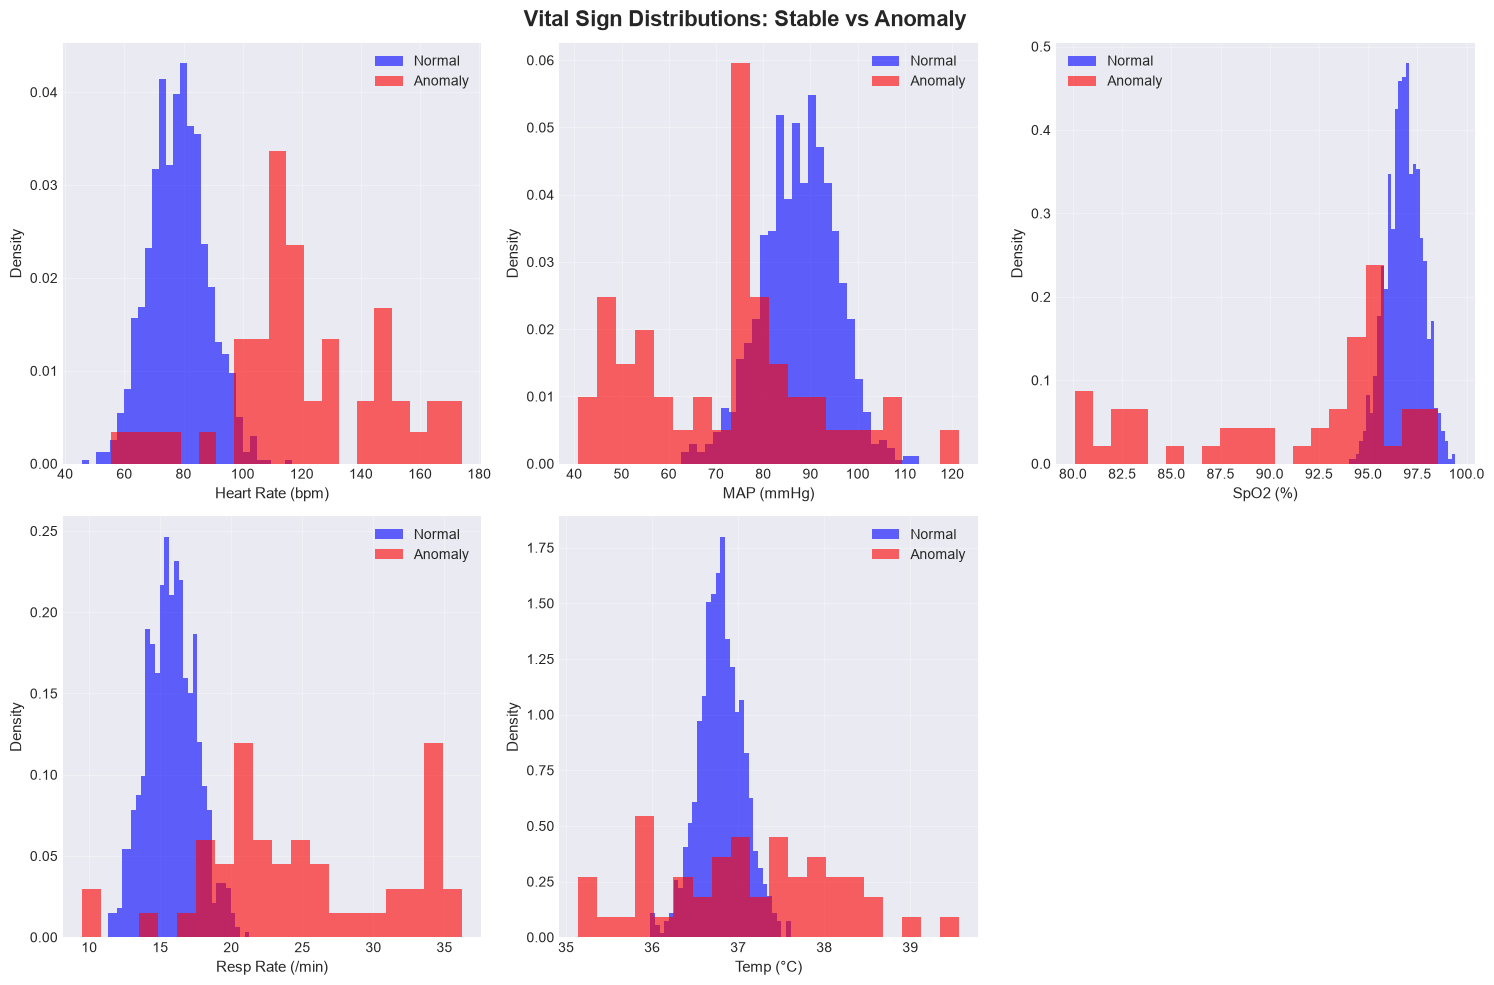

In [4]:
# Visualize distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Vital Sign Distributions: Stable vs Anomaly', fontsize=16, fontweight='bold')

for idx, feature in enumerate(feature_names):
    ax = axes[idx // 3, idx % 3]
    
    # Plot distributions
    df[df['True Label'] == 'Normal'][feature].hist(
        ax=ax, bins=30, alpha=0.6, label='Normal', color='blue', density=True
    )
    df[df['True Label'] == 'Anomaly'][feature].hist(
        ax=ax, bins=20, alpha=0.6, label='Anomaly', color='red', density=True
    )
    
    ax.set_xlabel(feature, fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.legend()
    ax.grid(alpha=0.3)

# Remove extra subplot
fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

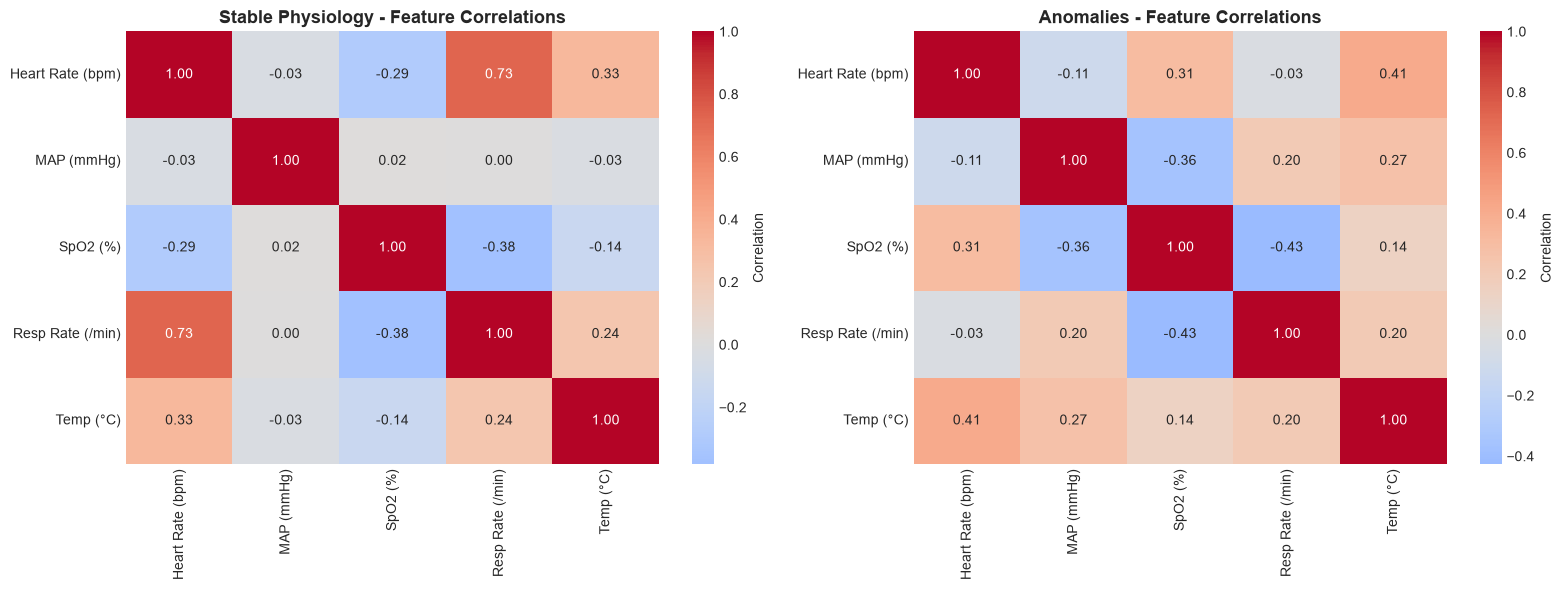


Key Observations:
- Stable physiology shows strong correlations (e.g., Resp Rate ↔ SpO2)
- Anomalies often break these correlations
- This makes them 'easier to isolate' in the feature space


In [5]:
# Correlation analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Normal data correlation
normal_corr = df[df['True Label'] == 'Normal'][feature_names].corr()
sns.heatmap(normal_corr, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, ax=axes[0], cbar_kws={'label': 'Correlation'})
axes[0].set_title('Stable Physiology - Feature Correlations', fontsize=13, fontweight='bold')

# Anomaly data correlation
anomaly_corr = df[df['True Label'] == 'Anomaly'][feature_names].corr()
sns.heatmap(anomaly_corr, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, ax=axes[1], cbar_kws={'label': 'Correlation'})
axes[1].set_title('Anomalies - Feature Correlations', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nKey Observations:")
print("- Stable physiology shows strong correlations (e.g., Resp Rate ↔ SpO2)")
print("- Anomalies often break these correlations")
print("- This makes them 'easier to isolate' in the feature space")

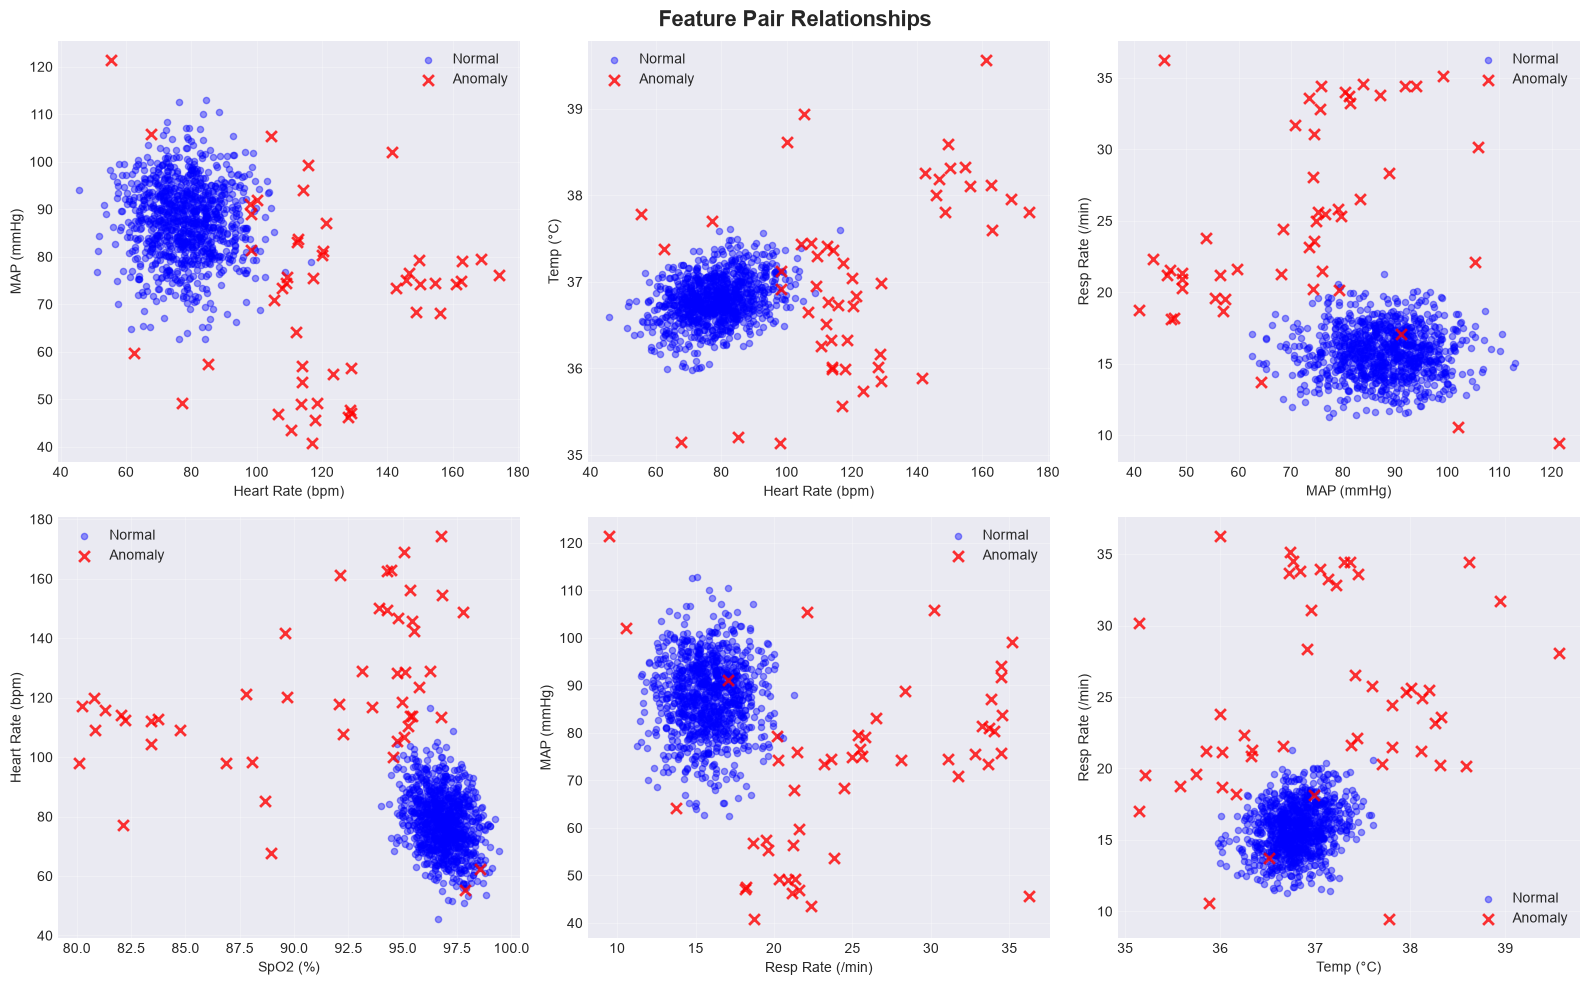

In [6]:
# 2D scatter plots of key feature pairs
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Feature Pair Relationships', fontsize=16, fontweight='bold')

feature_pairs = [
    (0, 1), (0, 4), (1, 3),
    (2, 0), (3, 1), (4, 3)
]

for idx, (i, j) in enumerate(feature_pairs):
    ax = axes[idx // 3, idx % 3]
    
    # Plot normal points
    normal_mask = y_true == 1
    ax.scatter(X[normal_mask, i], X[normal_mask, j], 
               alpha=0.4, s=20, c='blue', label='Normal')
    
    # Plot anomalies
    anomaly_mask = y_true == -1
    ax.scatter(X[anomaly_mask, i], X[anomaly_mask, j], 
               alpha=0.8, s=60, c='red', marker='x', linewidths=2, label='Anomaly')
    
    ax.set_xlabel(feature_names[i], fontsize=10)
    ax.set_ylabel(feature_names[j], fontsize=10)
    ax.legend(loc='best')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Train Isolation Forest Model

### Key Hyperparameters

1. **contamination**: Expected proportion of anomalies (default: 'auto')
   - Affects the threshold for anomaly scores
   - Should match approximate anomaly rate if known

2. **n_estimators**: Number of isolation trees (default: 100)
   - More trees = more stable predictions
   - Diminishing returns after ~100-200

3. **max_samples**: Number of samples to draw for each tree (default: 'auto')
   - Smaller values = faster training, more diverse trees
   - 'auto' uses min(256, n_samples)

4. **max_features**: Number of features to draw for each tree (default: 1.0)
   - Can help with high-dimensional data
   - 1.0 uses all features

5. **random_state**: Seed for reproducibility

In [7]:
# Standardize features (important for distance-based methods)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train Isolation Forest
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.05,  # Expected 5% anomalies
    max_samples='auto',
    random_state=42,
    n_jobs=-1
)

# Fit and predict
y_pred = iso_forest.fit_predict(X_scaled)

# Get anomaly scores (negative = more anomalous)
anomaly_scores = iso_forest.score_samples(X_scaled)

# Convert scores to [0, 1] range (higher = more anomalous)
# Using the formula from the paper
anomaly_scores_normalized = -anomaly_scores  # Flip sign

print("Model trained successfully!")
print(f"\nPredictions:")
print(f"  - Normal: {sum(y_pred == 1)}")
print(f"  - Anomalies detected: {sum(y_pred == -1)}")
print(f"\nAnomaly Score Statistics:")
print(f"  - Min: {anomaly_scores.min():.3f}")
print(f"  - Max: {anomaly_scores.max():.3f}")
print(f"  - Mean: {anomaly_scores.mean():.3f}")
print(f"  - Std: {anomaly_scores.std():.3f}")

Model trained successfully!

Predictions:
  - Normal: 997
  - Anomalies detected: 53

Anomaly Score Statistics:
  - Min: -0.736
  - Max: -0.346
  - Mean: -0.409
  - Std: 0.068


## 5. Model Evaluation

Classification Report:
              precision    recall  f1-score   support

     Anomaly       0.94      1.00      0.97        50
      Normal       1.00      1.00      1.00      1000

    accuracy                           1.00      1050
   macro avg       0.97      1.00      0.98      1050
weighted avg       1.00      1.00      1.00      1050



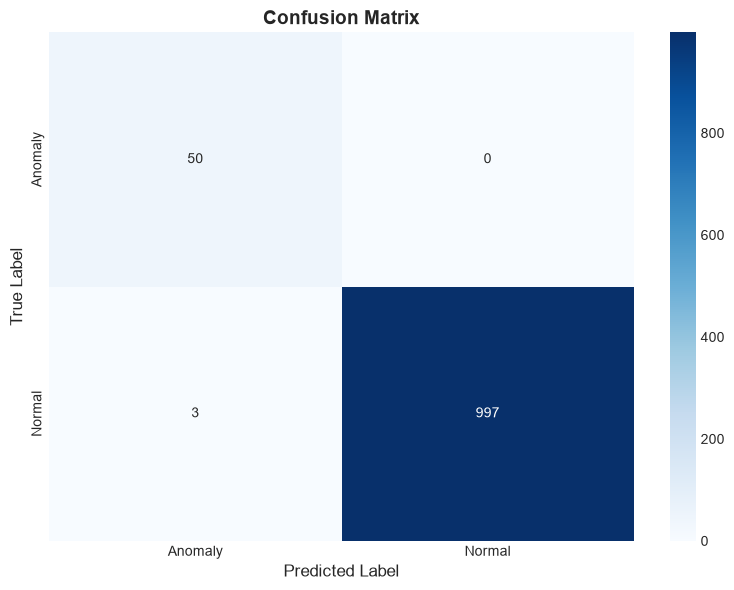


Detailed Metrics:
  - True Positives (anomalies caught): 997
  - False Positives (false alarms): 0
  - False Negatives (missed anomalies): 3
  - True Negatives (correct normal): 50

  - Precision: 1.000
  - Recall: 0.997
  - F1-Score: 0.998


In [8]:
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    roc_auc_score, 
    precision_recall_curve,
    roc_curve,
    average_precision_score
)

# Classification report
print("Classification Report:")
print("="*60)
print(classification_report(y_true, y_pred, target_names=['Anomaly', 'Normal']))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Anomaly', 'Normal'], 
            yticklabels=['Anomaly', 'Normal'],
            ax=ax)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Calculate metrics
tn, fp, fn, tp = cm.ravel()
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"\nDetailed Metrics:")
print(f"  - True Positives (anomalies caught): {tp}")
print(f"  - False Positives (false alarms): {fp}")
print(f"  - False Negatives (missed anomalies): {fn}")
print(f"  - True Negatives (correct normal): {tn}")
print(f"\n  - Precision: {precision:.3f}")
print(f"  - Recall: {recall:.3f}")
print(f"  - F1-Score: {f1:.3f}")

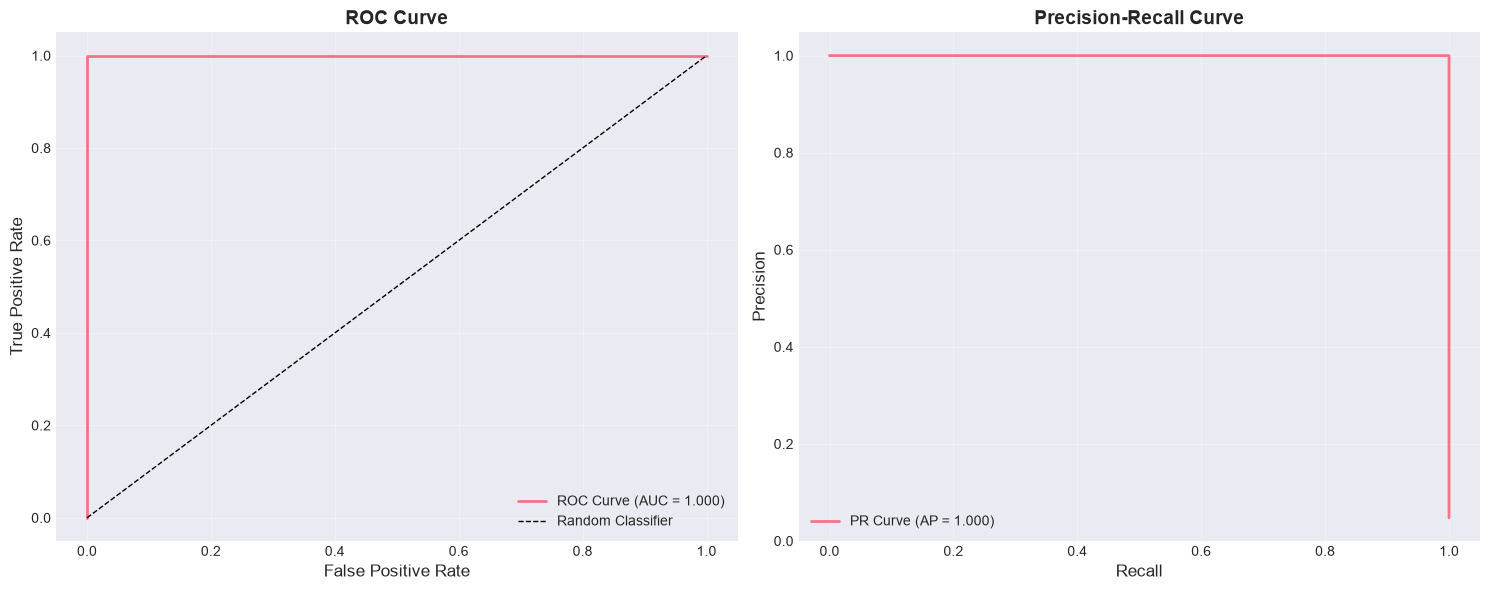


Curve Metrics:
  - ROC AUC: 1.000 (1.0 = perfect, 0.5 = random)
  - Average Precision: 1.000


In [9]:
# ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Convert labels to binary: 1 = anomaly (positive class), 0 = normal
y_true_binary = (y_true == -1).astype(int)

# ROC Curve
# Higher -anomaly_scores means more anomalous, which is our positive class
fpr, tpr, thresholds_roc = roc_curve(y_true_binary, -anomaly_scores)
roc_auc = roc_auc_score(y_true_binary, -anomaly_scores)

axes[0].plot(fpr, tpr, linewidth=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate', fontsize=12)
axes[0].set_title('ROC Curve', fontsize=14, fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

# Precision-Recall Curve
precision_curve, recall_curve, thresholds_pr = precision_recall_curve(y_true_binary, -anomaly_scores)
avg_precision = average_precision_score(y_true_binary, -anomaly_scores)

axes[1].plot(recall_curve, precision_curve, linewidth=2, 
             label=f'PR Curve (AP = {avg_precision:.3f})')
axes[1].set_xlabel('Recall', fontsize=12)
axes[1].set_ylabel('Precision', fontsize=12)
axes[1].set_title('Precision-Recall Curve', fontsize=14, fontweight='bold')
axes[1].legend(loc='best')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nCurve Metrics:")
print(f"  - ROC AUC: {roc_auc:.3f} (1.0 = perfect, 0.5 = random)")
print(f"  - Average Precision: {avg_precision:.3f}")

## 6. Visualizing Anomaly Scores

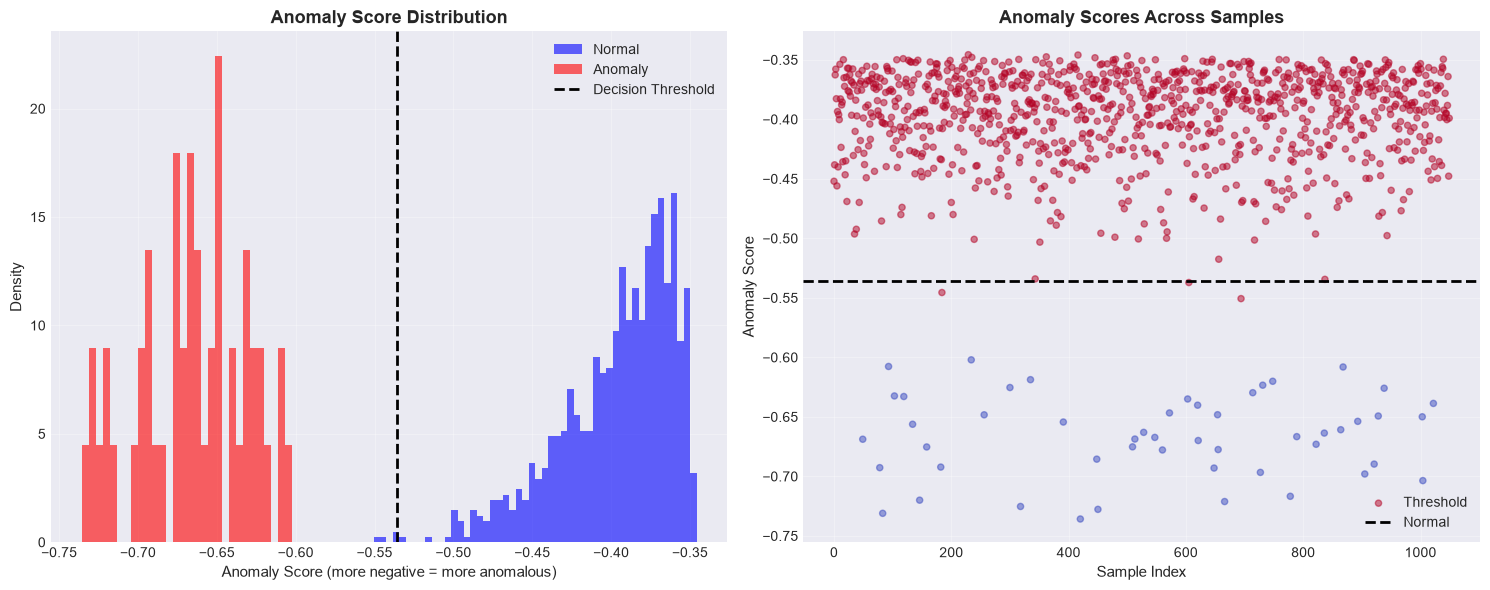

In [10]:
# Anomaly score distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Score distribution by true label
axes[0].hist(anomaly_scores[y_true == 1], bins=50, alpha=0.6, 
             label='Normal', color='blue', density=True)
axes[0].hist(anomaly_scores[y_true == -1], bins=30, alpha=0.6, 
             label='Anomaly', color='red', density=True)
axes[0].axvline(iso_forest.offset_, color='black', linestyle='--', 
                linewidth=2, label='Decision Threshold')
axes[0].set_xlabel('Anomaly Score (more negative = more anomalous)', fontsize=11)
axes[0].set_ylabel('Density', fontsize=11)
axes[0].set_title('Anomaly Score Distribution', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Score vs index (temporal view)
axes[1].scatter(range(len(anomaly_scores)), anomaly_scores, 
                c=y_true, cmap='coolwarm', alpha=0.5, s=20)
axes[1].axhline(iso_forest.offset_, color='black', linestyle='--', 
                linewidth=2, label='Decision Threshold')
axes[1].set_xlabel('Sample Index', fontsize=11)
axes[1].set_ylabel('Anomaly Score', fontsize=11)
axes[1].set_title('Anomaly Scores Across Samples', fontsize=13, fontweight='bold')
axes[1].legend(['Threshold', 'Normal', 'Anomaly'])
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Define helper function for tracing paths through isolation trees
def get_path_info(tree, sample, node=0, depth=0, path=[]):
    """
    Trace the path of a sample through an isolation tree.
    
    Parameters:
    -----------
    tree : IsolationTree
        The isolation tree to trace through
    sample : array-like
        The sample to trace
    node : int
        Current node index (default: 0 = root)
    depth : int
        Current depth in the tree
    path : list
        List of decisions made along the path
    
    Returns:
    --------
    depth : int
        Final depth where sample was isolated
    path : list
        List of tuples (depth, feature_idx, threshold, direction, actual_value)
    """
    from sklearn.tree import _tree
    
    # Get tree structure
    feature = tree.tree_.feature
    threshold = tree.tree_.threshold
    
    path_copy = path.copy()
    
    # Check if leaf node
    if feature[node] == _tree.TREE_UNDEFINED:
        return depth, path_copy
    
    # Determine which way to go
    if sample[feature[node]] <= threshold[node]:
        path_copy.append((depth, feature[node], threshold[node], "≤", sample[feature[node]]))
        return get_path_info(tree, sample, tree.tree_.children_left[node], depth + 1, path_copy)
    else:
        path_copy.append((depth, feature[node], threshold[node], ">", sample[feature[node]]))
        return get_path_info(tree, sample, tree.tree_.children_right[node], depth + 1, path_copy)

print("Helper functions defined successfully!")

Helper functions defined successfully!


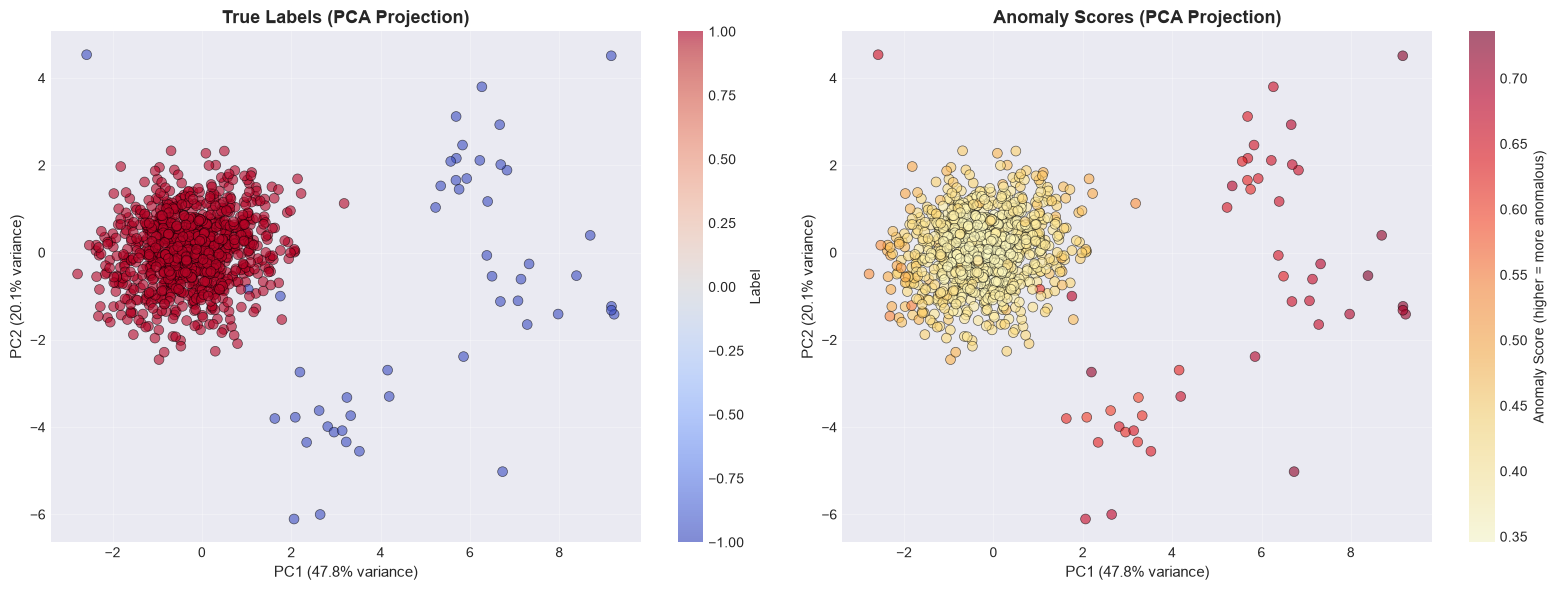


PCA Explained Variance:
  - PC1: 47.8%
  - PC2: 20.1%
  - Total: 67.9%


In [12]:
# Visualize in 2D using PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# True labels
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], 
                           c=y_true, cmap='coolwarm', 
                           alpha=0.6, s=50, edgecolors='k', linewidth=0.5)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)', fontsize=11)
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)', fontsize=11)
axes[0].set_title('True Labels (PCA Projection)', fontsize=13, fontweight='bold')
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Label', fontsize=10)
axes[0].grid(alpha=0.3)

# Predicted labels with score intensity
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], 
                           c=-anomaly_scores,  # Flip for visualization
                           cmap='YlOrRd', 
                           alpha=0.6, s=50, edgecolors='k', linewidth=0.5)
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)', fontsize=11)
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)', fontsize=11)
axes[1].set_title('Anomaly Scores (PCA Projection)', fontsize=13, fontweight='bold')
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Anomaly Score (higher = more anomalous)', fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nPCA Explained Variance:")
print(f"  - PC1: {pca.explained_variance_ratio_[0]:.1%}")
print(f"  - PC2: {pca.explained_variance_ratio_[1]:.1%}")
print(f"  - Total: {pca.explained_variance_ratio_.sum():.1%}")

In [13]:
# Visualize in 3D using PCA with Plotly
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_scaled)

# Create a DataFrame for easier plotting
plot_df = pd.DataFrame({
    'PC1': X_pca_3d[:, 0],
    'PC2': X_pca_3d[:, 1],
    'PC3': X_pca_3d[:, 2],
    'True Label': ['Anomaly' if y == -1 else 'Normal' for y in y_true],
    'Anomaly Score': -anomaly_scores,  # Flip for visualization (higher = more anomalous)
    'Sample Index': range(len(X))
})

# Create two side-by-side 3D plots
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('True Labels (3D PCA)', 'Anomaly Scores (3D PCA)'),
    specs=[[{'type': 'scatter3d'}, {'type': 'scatter3d'}]],
    horizontal_spacing=0.1
)

# Plot 1: True Labels
for label, color in [('Normal', 'blue'), ('Anomaly', 'red')]:
    mask = plot_df['True Label'] == label
    fig.add_trace(
        go.Scatter3d(
            x=plot_df[mask]['PC1'],
            y=plot_df[mask]['PC2'],
            z=plot_df[mask]['PC3'],
            mode='markers',
            name=label,
            marker=dict(
                size=4 if label == 'Normal' else 8,
                color=color,
                opacity=0.6 if label == 'Normal' else 0.9,
                symbol='circle' if label == 'Normal' else 'x',
                line=dict(width=0.5, color='black') if label == 'Anomaly' else dict(width=0)
            ),
            text=[f"Sample {i}<br>{label}" for i in plot_df[mask]['Sample Index']],
            hovertemplate='<b>%{text}</b><br>PC1: %{x:.2f}<br>PC2: %{y:.2f}<br>PC3: %{z:.2f}<extra></extra>'
        ),
        row=1, col=1
    )

# Plot 2: Anomaly Scores (continuous color scale)
fig.add_trace(
    go.Scatter3d(
        x=plot_df['PC1'],
        y=plot_df['PC2'],
        z=plot_df['PC3'],
        mode='markers',
        name='Anomaly Score',
        marker=dict(
            size=4,
            color=plot_df['Anomaly Score'],
            colorscale='YlOrRd',
            opacity=0.7,
            colorbar=dict(
                title='Anomaly<br>Score',
                x=1.15,
                thickness=15,
                len=0.7
            ),
            line=dict(width=0.5, color='black')
        ),
        text=[f"Sample {i}<br>Score: {score:.3f}<br>{label}" 
              for i, score, label in zip(plot_df['Sample Index'], 
                                        plot_df['Anomaly Score'], 
                                        plot_df['True Label'])],
        hovertemplate='<b>%{text}</b><br>PC1: %{x:.2f}<br>PC2: %{y:.2f}<br>PC3: %{z:.2f}<extra></extra>',
        showlegend=False
    ),
    row=1, col=2
)

# Update layout
fig.update_layout(
    title=dict(
        text='3D PCA Visualization of ICU Telemetry Anomalies',
        font=dict(size=18, family='Arial Black')
    ),
    height=600,
    showlegend=True,
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor='rgba(255,255,255,0.8)',
        bordercolor='black',
        borderwidth=1
    ),
    margin=dict(l=0, r=0, t=80, b=0)
)

# Update 3D scene properties
scene_config = dict(
    xaxis=dict(
        title=f'PC1 ({pca_3d.explained_variance_ratio_[0]:.1%} var)',
        backgroundcolor='rgb(230, 230,230)',
        gridcolor='white'
    ),
    yaxis=dict(
        title=f'PC2 ({pca_3d.explained_variance_ratio_[1]:.1%} var)',
        backgroundcolor='rgb(230, 230,230)',
        gridcolor='white'
    ),
    zaxis=dict(
        title=f'PC3 ({pca_3d.explained_variance_ratio_[2]:.1%} var)',
        backgroundcolor='rgb(230, 230,230)',
        gridcolor='white'
    ),
    camera=dict(
        eye=dict(x=1.5, y=1.5, z=1.3)
    )
)

fig.update_scenes(scene_config, row=1, col=1)
fig.update_scenes(scene_config, row=1, col=2)

fig.show()

print(f"\n3D PCA Explained Variance:")
print(f"  - PC1: {pca_3d.explained_variance_ratio_[0]:.1%}")
print(f"  - PC2: {pca_3d.explained_variance_ratio_[1]:.1%}")
print(f"  - PC3: {pca_3d.explained_variance_ratio_[2]:.1%}")
print(f"  - Total: {pca_3d.explained_variance_ratio_.sum():.1%}")
print(f"\n💡 Tip: You can rotate, zoom, and pan the 3D plots with your mouse!")
print("     Click and drag to rotate, scroll to zoom, shift+drag to pan.")


3D PCA Explained Variance:
  - PC1: 47.8%
  - PC2: 20.1%
  - PC3: 18.0%
  - Total: 85.8%

💡 Tip: You can rotate, zoom, and pan the 3D plots with your mouse!
     Click and drag to rotate, scroll to zoom, shift+drag to pan.


## 6.5 Isolation Path Visualization

Let's visualize how Isolation Forest actually works by examining the paths that samples take through the isolation trees. This will demonstrate the key insight: **anomalies have shorter isolation paths than normal points**.

### Text-Based Path Comparison

First, let's trace the exact path that a normal sample and an anomaly take through one of the isolation trees.

In [14]:
# Select one normal point and one anomaly for visualization
normal_idx = np.where(y_true == 1)[0][0]  # First normal point
anomaly_idx = np.where(y_true == -1)[0][0]  # First anomaly

print("=" * 80)
print("COMPARING ISOLATION PATHS")
print("=" * 80)
print(f"\n📍 Normal Sample #{normal_idx}:")
for i, (fname, val) in enumerate(zip(feature_names, X[normal_idx])):
    print(f"   {fname:25s}: {val:8.2f}")
print(f"   Anomaly Score: {anomaly_scores[normal_idx]:.4f}")

print(f"\n🔴 Anomaly Sample #{anomaly_idx}:")
for i, (fname, val) in enumerate(zip(feature_names, X[anomaly_idx])):
    print(f"   {fname:25s}: {val:8.2f}")
print(f"   Anomaly Score: {anomaly_scores[anomaly_idx]:.4f}")
print("=" * 80)

# Get paths for both samples through the first tree
first_tree = iso_forest.estimators_[0]
normal_depth, normal_path = get_path_info(first_tree, X_scaled[normal_idx])
anomaly_depth, anomaly_path = get_path_info(first_tree, X_scaled[anomaly_idx])

print(f"\n🌲 Tree #1 Isolation Paths:")
print(f"\n📍 Normal Point Path (Depth = {normal_depth}):")
for depth, feat_idx, thresh, direction, value in normal_path:
    indent = "  " * depth
    print(f"{indent}├─ {feature_names[feat_idx]} {direction} {thresh:.2f}  [actual: {value:.2f}]")
print(f"{'  ' * normal_depth}└─ ✓ ISOLATED at depth {normal_depth}")

print(f"\n🔴 Anomaly Path (Depth = {anomaly_depth}):")
for depth, feat_idx, thresh, direction, value in anomaly_path:
    indent = "  " * depth
    print(f"{indent}├─ {feature_names[feat_idx]} {direction} {thresh:.2f}  [actual: {value:.2f}]")
print(f"{'  ' * anomaly_depth}└─ ✓ ISOLATED at depth {anomaly_depth}")

print(f"\n💡 Notice: The anomaly was isolated {abs(normal_depth - anomaly_depth)} level(s) earlier!")
print("=" * 80)

COMPARING ISOLATION PATHS

📍 Normal Sample #0:
   Heart Rate (bpm)         :    84.21
   MAP (mmHg)               :    62.59
   SpO2 (%)                 :    96.51
   Resp Rate (/min)         :    17.10
   Temp (°C)                :    36.67
   Anomaly Score: -0.4521

🔴 Anomaly Sample #49:
   Heart Rate (bpm)         :   112.10
   MAP (mmHg)               :    64.21
   SpO2 (%)                 :    83.40
   Resp Rate (/min)         :    13.73
   Temp (°C)                :    36.51
   Anomaly Score: -0.6688

🌲 Tree #1 Isolation Paths:

📍 Normal Point Path (Depth = 6):
├─ Heart Rate (bpm) ≤ 1.16  [actual: 0.28]
  ├─ Heart Rate (bpm) ≤ 0.63  [actual: 0.28]
    ├─ MAP (mmHg) ≤ -0.95  [actual: -2.61]
      ├─ Resp Rate (/min) > 0.08  [actual: 0.30]
        ├─ Resp Rate (/min) ≤ 0.49  [actual: 0.30]
          ├─ Temp (°C) ≤ -0.04  [actual: -0.42]
            └─ ✓ ISOLATED at depth 6

🔴 Anomaly Path (Depth = 4):
├─ Heart Rate (bpm) > 1.16  [actual: 2.22]
  ├─ Resp Rate (/min) ≤ 0.86  [actual:

### Interactive Tree Diagram

Now let's visualize the tree structure with an interactive Plotly diagram showing color-coded paths.

In [15]:
# Create an interactive tree visualization using Plotly
def create_tree_visualization(tree, normal_sample, anomaly_sample, max_depth=6):
    """Create an interactive tree diagram showing paths for normal and anomaly samples."""
    from sklearn.tree import _tree
    import plotly.graph_objects as go
    
    # Data structures for the tree
    nodes_x = []
    nodes_y = []
    nodes_text = []
    nodes_color = []
    
    edges_x = []
    edges_y = []
    
    # Track which nodes are on each path
    normal_path_nodes = set()
    anomaly_path_nodes = set()
    
    def get_path_nodes(sample, node=0, path_set=None):
        """Get all nodes in the path for a sample."""
        if path_set is None:
            path_set = set()
        
        path_set.add(node)
        feature = tree.tree_.feature
        threshold = tree.tree_.threshold
        
        if feature[node] == _tree.TREE_UNDEFINED:  # Leaf
            return path_set
        
        if sample[feature[node]] <= threshold[node]:
            return get_path_nodes(sample, tree.tree_.children_left[node], path_set)
        else:
            return get_path_nodes(sample, tree.tree_.children_right[node], path_set)
    
    # Get path nodes
    normal_path_nodes = get_path_nodes(normal_sample)
    anomaly_path_nodes = get_path_nodes(anomaly_sample)
    
    def add_nodes(node=0, x=0, y=0, layer=0, x_offset=4):
        """Recursively add nodes to the visualization."""
        if layer > max_depth:
            return
        
        feature = tree.tree_.feature
        threshold = tree.tree_.threshold
        
        # Determine node color based on which path it's on
        if node in normal_path_nodes and node in anomaly_path_nodes:
            color = 'purple'  # Both paths
        elif node in normal_path_nodes:
            color = 'blue'  # Normal path only
        elif node in anomaly_path_nodes:
            color = 'red'  # Anomaly path only
        else:
            color = 'lightgray'  # Not on either path
        
        # Create node label
        if feature[node] == _tree.TREE_UNDEFINED:  # Leaf
            label = f"LEAF<br>Depth: {layer}"
        else:
            feat_name = feature_names[feature[node]]
            label = f"{feat_name}<br>≤ {threshold[node]:.2f}"
        
        nodes_x.append(x)
        nodes_y.append(-y)
        nodes_text.append(label)
        nodes_color.append(color)
        
        # Add children
        if feature[node] != _tree.TREE_UNDEFINED and layer < max_depth:
            left_child = tree.tree_.children_left[node]
            right_child = tree.tree_.children_right[node]
            
            # Calculate positions for children
            left_x = x - x_offset / (layer + 1)
            right_x = x + x_offset / (layer + 1)
            child_y = y + 1
            
            # Add edges
            edges_x.extend([x, left_x, None, x, right_x, None])
            edges_y.extend([-y, -child_y, None, -y, -child_y, None])
            
            # Recurse
            add_nodes(left_child, left_x, child_y, layer + 1, x_offset)
            add_nodes(right_child, right_x, child_y, layer + 1, x_offset)
    
    # Build the tree
    add_nodes()
    
    # Create the plot
    fig = go.Figure()
    
    # Add edges
    fig.add_trace(go.Scatter(
        x=edges_x, y=edges_y,
        mode='lines',
        line=dict(color='gray', width=1),
        hoverinfo='none',
        showlegend=False
    ))
    
    # Add nodes
    fig.add_trace(go.Scatter(
        x=nodes_x, y=nodes_y,
        mode='markers+text',
        marker=dict(
            size=25,
            color=nodes_color,
            line=dict(color='black', width=2)
        ),
        text=nodes_text,
        textposition='middle center',
        textfont=dict(size=8, color='white'),
        hovertemplate='<b>%{text}</b><extra></extra>',
        showlegend=False
    ))
    
    # Update layout
    fig.update_layout(
        title=dict(
            text='🌲 Isolation Tree Path Comparison<br><sub>Purple=Both paths | Blue=Normal only | Red=Anomaly only | Gray=Not visited</sub>',
            font=dict(size=16, family='Arial Black')
        ),
        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
        height=500,
        plot_bgcolor='white',
        margin=dict(l=20, r=20, t=80, b=20)
    )
    
    return fig

# Create and show the visualization
fig = create_tree_visualization(first_tree, X_scaled[normal_idx], X_scaled[anomaly_idx], max_depth=5)
fig.show()

print("\n" + "=" * 80)
print("TREE VISUALIZATION LEGEND")
print("=" * 80)
print("🟣 Purple nodes: Both samples pass through here")
print("🔵 Blue nodes:   Only the normal sample passes through here")
print("🔴 Red nodes:    Only the anomaly passes through here")
print("⚪ Gray nodes:   Neither sample visits these nodes")
print("=" * 80)


TREE VISUALIZATION LEGEND
🟣 Purple nodes: Both samples pass through here
🔵 Blue nodes:   Only the normal sample passes through here
🔴 Red nodes:    Only the anomaly passes through here
⚪ Gray nodes:   Neither sample visits these nodes


### Path Length Distribution Analysis

Finally, let's analyze the path lengths across all trees to statistically confirm that anomalies have shorter paths.

Calculating average path lengths across all 100 trees...
(This may take a moment...)


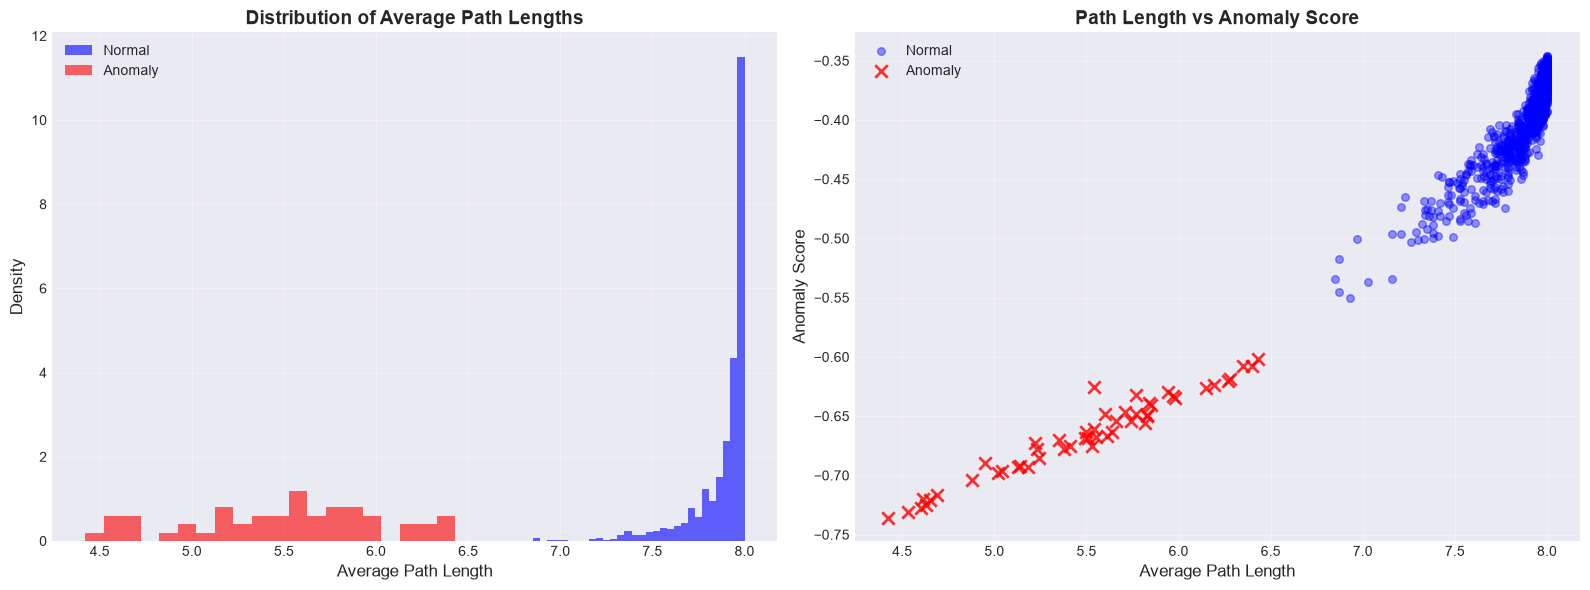


PATH LENGTH STATISTICS
Normal samples:
  - Mean path length: 7.88
  - Std path length:  0.17

Anomaly samples:
  - Mean path length: 5.49
  - Std path length:  0.52

💡 Anomalies have 2.39 shorter paths on average!


In [16]:
# Calculate average path lengths across all trees for all samples
def calculate_average_path_length(forest, X_samples):
    """Calculate average path length for each sample across all trees."""
    path_lengths = []
    
    for sample in X_samples:
        sample_paths = []
        for tree in forest.estimators_:
            depth, _ = get_path_info(tree, sample)
            sample_paths.append(depth)
        path_lengths.append(np.mean(sample_paths))
    
    return np.array(path_lengths)

print("Calculating average path lengths across all 100 trees...")
print("(This may take a moment...)")

avg_path_lengths = calculate_average_path_length(iso_forest, X_scaled)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram of path lengths
axes[0].hist(avg_path_lengths[y_true == 1], bins=30, alpha=0.6, 
             label='Normal', color='blue', density=True)
axes[0].hist(avg_path_lengths[y_true == -1], bins=20, alpha=0.6, 
             label='Anomaly', color='red', density=True)
axes[0].set_xlabel('Average Path Length', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)
axes[0].set_title('Distribution of Average Path Lengths', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Scatter plot: Path Length vs Anomaly Score
axes[1].scatter(avg_path_lengths[y_true == 1], anomaly_scores[y_true == 1],
                alpha=0.4, s=30, c='blue', label='Normal')
axes[1].scatter(avg_path_lengths[y_true == -1], anomaly_scores[y_true == -1],
                alpha=0.8, s=80, c='red', marker='x', linewidths=2, label='Anomaly')
axes[1].set_xlabel('Average Path Length', fontsize=12)
axes[1].set_ylabel('Anomaly Score', fontsize=12)
axes[1].set_title('Path Length vs Anomaly Score', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("PATH LENGTH STATISTICS")
print("=" * 80)
print(f"Normal samples:")
print(f"  - Mean path length: {avg_path_lengths[y_true == 1].mean():.2f}")
print(f"  - Std path length:  {avg_path_lengths[y_true == 1].std():.2f}")
print(f"\nAnomaly samples:")
print(f"  - Mean path length: {avg_path_lengths[y_true == -1].mean():.2f}")
print(f"  - Std path length:  {avg_path_lengths[y_true == -1].std():.2f}")
print(f"\n💡 Anomalies have {avg_path_lengths[y_true == 1].mean() - avg_path_lengths[y_true == -1].mean():.2f} shorter paths on average!")
print("=" * 80)

Calculating average path lengths across all 100 trees...
(This may take a moment...)


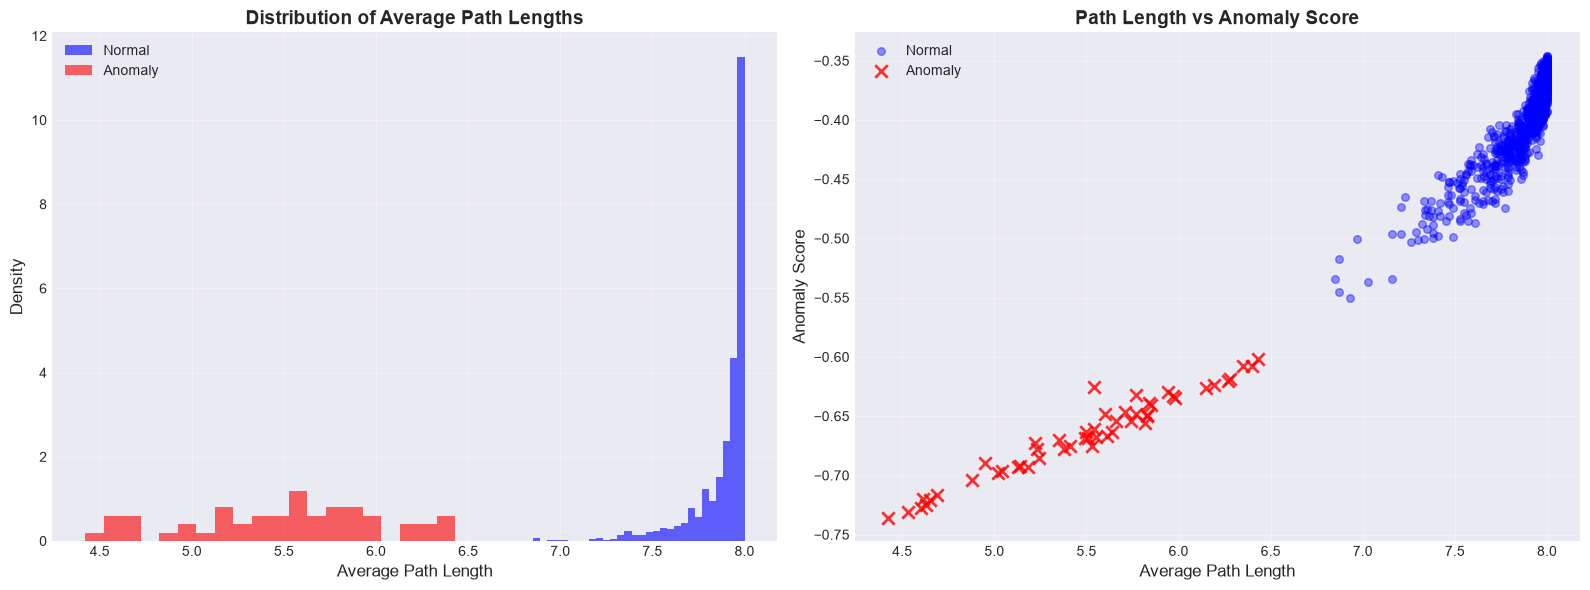


PATH LENGTH STATISTICS
Normal samples:
  - Mean path length: 7.88
  - Std path length:  0.17

Anomaly samples:
  - Mean path length: 5.49
  - Std path length:  0.52

💡 Anomalies have 2.39 shorter paths on average!


In [17]:
# Calculate average path lengths across all trees for all samples
def calculate_average_path_length(forest, X_samples):
    """Calculate average path length for each sample across all trees."""
    path_lengths = []
    
    for sample in X_samples:
        sample_paths = []
        for tree in forest.estimators_:
            depth, _ = get_path_info(tree, sample)
            sample_paths.append(depth)
        path_lengths.append(np.mean(sample_paths))
    
    return np.array(path_lengths)

print("Calculating average path lengths across all 100 trees...")
print("(This may take a moment...)")

avg_path_lengths = calculate_average_path_length(iso_forest, X_scaled)

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram of path lengths
axes[0].hist(avg_path_lengths[y_true == 1], bins=30, alpha=0.6, 
             label='Normal', color='blue', density=True)
axes[0].hist(avg_path_lengths[y_true == -1], bins=20, alpha=0.6, 
             label='Anomaly', color='red', density=True)
axes[0].set_xlabel('Average Path Length', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)
axes[0].set_title('Distribution of Average Path Lengths', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Scatter plot: Path Length vs Anomaly Score
axes[1].scatter(avg_path_lengths[y_true == 1], anomaly_scores[y_true == 1],
                alpha=0.4, s=30, c='blue', label='Normal')
axes[1].scatter(avg_path_lengths[y_true == -1], anomaly_scores[y_true == -1],
                alpha=0.8, s=80, c='red', marker='x', linewidths=2, label='Anomaly')
axes[1].set_xlabel('Average Path Length', fontsize=12)
axes[1].set_ylabel('Anomaly Score', fontsize=12)
axes[1].set_title('Path Length vs Anomaly Score', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("PATH LENGTH STATISTICS")
print("=" * 80)
print(f"Normal samples:")
print(f"  - Mean path length: {avg_path_lengths[y_true == 1].mean():.2f}")
print(f"  - Std path length:  {avg_path_lengths[y_true == 1].std():.2f}")
print(f"\nAnomaly samples:")
print(f"  - Mean path length: {avg_path_lengths[y_true == -1].mean():.2f}")
print(f"  - Std path length:  {avg_path_lengths[y_true == -1].std():.2f}")
print(f"\n💡 Anomalies have {avg_path_lengths[y_true == 1].mean() - avg_path_lengths[y_true == -1].mean():.2f} shorter paths on average!")
print("=" * 80)

In [18]:
# Select one normal point and one anomaly for visualization
normal_idx = np.where(y_true == 1)[0][0]  # First normal point
anomaly_idx = np.where(y_true == -1)[0][0]  # First anomaly

print("=" * 80)
print("COMPARING ISOLATION PATHS")
print("=" * 80)
print(f"\n📍 Normal Sample #{normal_idx}:")
for i, (fname, val) in enumerate(zip(feature_names, X[normal_idx])):
    print(f"   {fname:25s}: {val:8.2f}")
print(f"   Anomaly Score: {anomaly_scores[normal_idx]:.4f}")

print(f"\n🔴 Anomaly Sample #{anomaly_idx}:")
for i, (fname, val) in enumerate(zip(feature_names, X[anomaly_idx])):
    print(f"   {fname:25s}: {val:8.2f}")
print(f"   Anomaly Score: {anomaly_scores[anomaly_idx]:.4f}")
print("=" * 80)

# Get paths for both samples through the first tree
first_tree = iso_forest.estimators_[0]
normal_depth, normal_path = get_path_info(first_tree, X_scaled[normal_idx])
anomaly_depth, anomaly_path = get_path_info(first_tree, X_scaled[anomaly_idx])

print(f"\n🌲 Tree #1 Isolation Paths:")
print(f"\n📍 Normal Point Path (Depth = {normal_depth}):")
for depth, feat_idx, thresh, direction, value in normal_path:
    indent = "  " * depth
    print(f"{indent}├─ {feature_names[feat_idx]} {direction} {thresh:.2f}  [actual: {value:.2f}]")
print(f"{'  ' * normal_depth}└─ ✓ ISOLATED at depth {normal_depth}")

print(f"\n🔴 Anomaly Path (Depth = {anomaly_depth}):")
for depth, feat_idx, thresh, direction, value in anomaly_path:
    indent = "  " * depth
    print(f"{indent}├─ {feature_names[feat_idx]} {direction} {thresh:.2f}  [actual: {value:.2f}]")
print(f"{'  ' * anomaly_depth}└─ ✓ ISOLATED at depth {anomaly_depth}")

print(f"\n💡 Notice: The anomaly was isolated {normal_depth - anomaly_depth} level(s) earlier!")
print("=" * 80)

COMPARING ISOLATION PATHS

📍 Normal Sample #0:
   Heart Rate (bpm)         :    84.21
   MAP (mmHg)               :    62.59
   SpO2 (%)                 :    96.51
   Resp Rate (/min)         :    17.10
   Temp (°C)                :    36.67
   Anomaly Score: -0.4521

🔴 Anomaly Sample #49:
   Heart Rate (bpm)         :   112.10
   MAP (mmHg)               :    64.21
   SpO2 (%)                 :    83.40
   Resp Rate (/min)         :    13.73
   Temp (°C)                :    36.51
   Anomaly Score: -0.6688

🌲 Tree #1 Isolation Paths:

📍 Normal Point Path (Depth = 6):
├─ Heart Rate (bpm) ≤ 1.16  [actual: 0.28]
  ├─ Heart Rate (bpm) ≤ 0.63  [actual: 0.28]
    ├─ MAP (mmHg) ≤ -0.95  [actual: -2.61]
      ├─ Resp Rate (/min) > 0.08  [actual: 0.30]
        ├─ Resp Rate (/min) ≤ 0.49  [actual: 0.30]
          ├─ Temp (°C) ≤ -0.04  [actual: -0.42]
            └─ ✓ ISOLATED at depth 6

🔴 Anomaly Path (Depth = 4):
├─ Heart Rate (bpm) > 1.16  [actual: 2.22]
  ├─ Resp Rate (/min) ≤ 0.86  [actual:

In [19]:
# Visualize in 3D using PCA with Plotly
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_scaled)

# Create a DataFrame for easier plotting
plot_df = pd.DataFrame({
    'PC1': X_pca_3d[:, 0],
    'PC2': X_pca_3d[:, 1],
    'PC3': X_pca_3d[:, 2],
    'True Label': ['Anomaly' if y == -1 else 'Normal' for y in y_true],
    'Anomaly Score': -anomaly_scores,  # Flip for visualization (higher = more anomalous)
    'Sample Index': range(len(X))
})

# Create two side-by-side 3D plots
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('True Labels (3D PCA)', 'Anomaly Scores (3D PCA)'),
    specs=[[{'type': 'scatter3d'}, {'type': 'scatter3d'}]],
    horizontal_spacing=0.1
)

# Plot 1: True Labels
for label, color in [('Normal', 'blue'), ('Anomaly', 'red')]:
    mask = plot_df['True Label'] == label
    fig.add_trace(
        go.Scatter3d(
            x=plot_df[mask]['PC1'],
            y=plot_df[mask]['PC2'],
            z=plot_df[mask]['PC3'],
            mode='markers',
            name=label,
            marker=dict(
                size=4 if label == 'Normal' else 8,
                color=color,
                opacity=0.6 if label == 'Normal' else 0.9,
                symbol='circle' if label == 'Normal' else 'x',
                line=dict(width=0.5, color='black') if label == 'Anomaly' else dict(width=0)
            ),
            text=[f"Sample {i}<br>{label}" for i in plot_df[mask]['Sample Index']],
            hovertemplate='<b>%{text}</b><br>PC1: %{x:.2f}<br>PC2: %{y:.2f}<br>PC3: %{z:.2f}<extra></extra>'
        ),
        row=1, col=1
    )

# Plot 2: Anomaly Scores (continuous color scale)
fig.add_trace(
    go.Scatter3d(
        x=plot_df['PC1'],
        y=plot_df['PC2'],
        z=plot_df['PC3'],
        mode='markers',
        name='Anomaly Score',
        marker=dict(
            size=4,
            color=plot_df['Anomaly Score'],
            colorscale='YlOrRd',
            opacity=0.7,
            colorbar=dict(
                title='Anomaly<br>Score',
                x=1.15,
                thickness=15,
                len=0.7
            ),
            line=dict(width=0.5, color='black')
        ),
        text=[f"Sample {i}<br>Score: {score:.3f}<br>{label}" 
              for i, score, label in zip(plot_df['Sample Index'], 
                                        plot_df['Anomaly Score'], 
                                        plot_df['True Label'])],
        hovertemplate='<b>%{text}</b><br>PC1: %{x:.2f}<br>PC2: %{y:.2f}<br>PC3: %{z:.2f}<extra></extra>',
        showlegend=False
    ),
    row=1, col=2
)

# Update layout
fig.update_layout(
    title=dict(
        text='3D PCA Visualization of ICU Telemetry Anomalies',
        font=dict(size=18, family='Arial Black')
    ),
    height=600,
    showlegend=True,
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor='rgba(255,255,255,0.8)',
        bordercolor='black',
        borderwidth=1
    ),
    margin=dict(l=0, r=0, t=80, b=0)
)

# Update 3D scene properties
scene_config = dict(
    xaxis=dict(
        title=f'PC1 ({pca_3d.explained_variance_ratio_[0]:.1%} var)',
        backgroundcolor='rgb(230, 230,230)',
        gridcolor='white'
    ),
    yaxis=dict(
        title=f'PC2 ({pca_3d.explained_variance_ratio_[1]:.1%} var)',
        backgroundcolor='rgb(230, 230,230)',
        gridcolor='white'
    ),
    zaxis=dict(
        title=f'PC3 ({pca_3d.explained_variance_ratio_[2]:.1%} var)',
        backgroundcolor='rgb(230, 230,230)',
        gridcolor='white'
    ),
    camera=dict(
        eye=dict(x=1.5, y=1.5, z=1.3)
    )
)

fig.update_scenes(scene_config, row=1, col=1)
fig.update_scenes(scene_config, row=1, col=2)

fig.show()

print(f"\n3D PCA Explained Variance:")
print(f"  - PC1: {pca_3d.explained_variance_ratio_[0]:.1%}")
print(f"  - PC2: {pca_3d.explained_variance_ratio_[1]:.1%}")
print(f"  - PC3: {pca_3d.explained_variance_ratio_[2]:.1%}")
print(f"  - Total: {pca_3d.explained_variance_ratio_.sum():.1%}")
print(f"\n💡 Tip: You can rotate, zoom, and pan the 3D plots with your mouse!")
print("     Click and drag to rotate, scroll to zoom, shift+drag to pan.")


3D PCA Explained Variance:
  - PC1: 47.8%
  - PC2: 20.1%
  - PC3: 18.0%
  - Total: 85.8%

💡 Tip: You can rotate, zoom, and pan the 3D plots with your mouse!
     Click and drag to rotate, scroll to zoom, shift+drag to pan.


## 7. Interactive Parameter Exploration

Use the sliders below to explore how different hyperparameters affect the model's performance.

In [20]:
def train_and_evaluate_interactive(n_estimators, contamination, max_samples_pct, max_features):
    """
    Train Isolation Forest with given parameters and display results.
    """
    # Calculate max_samples
    max_samples = int(len(X) * max_samples_pct) if max_samples_pct < 1.0 else 'auto'
    
    # Train model
    model = IsolationForest(
        n_estimators=n_estimators,
        contamination=contamination,
        max_samples=max_samples,
        max_features=max_features,
        random_state=42,
        n_jobs=-1
    )
    
    y_pred_temp = model.fit_predict(X_scaled)
    scores_temp = model.score_samples(X_scaled)
    
    # Convert labels to binary for ROC calculation
    y_true_binary = (y_true == -1).astype(int)
    
    # Calculate metrics
    cm_temp = confusion_matrix(y_true, y_pred_temp)
    tn, fp, fn, tp = cm_temp.ravel()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    try:
        roc_auc = roc_auc_score(y_true_binary, -scores_temp)
    except:
        roc_auc = 0
    
    # Visualize
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Confusion Matrix
    sns.heatmap(cm_temp, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Anomaly', 'Normal'],
                yticklabels=['Anomaly', 'Normal'],
                ax=axes[0])
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    axes[0].set_title('Confusion Matrix')
    
    # Score distribution
    axes[1].hist(scores_temp[y_true == 1], bins=50, alpha=0.6, 
                 label='Normal', color='blue', density=True)
    axes[1].hist(scores_temp[y_true == -1], bins=30, alpha=0.6, 
                 label='Anomaly', color='red', density=True)
    axes[1].axvline(model.offset_, color='black', linestyle='--', 
                    linewidth=2, label='Threshold')
    axes[1].set_xlabel('Anomaly Score')
    axes[1].set_ylabel('Density')
    axes[1].set_title('Score Distribution')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    
    # PCA visualization
    scatter = axes[2].scatter(X_pca[:, 0], X_pca[:, 1], 
                              c=-scores_temp, cmap='YlOrRd',
                              alpha=0.6, s=50, edgecolors='k', linewidth=0.5)
    axes[2].set_xlabel('PC1')
    axes[2].set_ylabel('PC2')
    axes[2].set_title('Anomaly Scores (PCA)')
    plt.colorbar(scatter, ax=axes[2], label='Anomaly Score')
    axes[2].grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print metrics
    print("\n" + "="*60)
    print(f"PERFORMANCE METRICS")
    print("="*60)
    print(f"Precision:    {precision:.3f}  (Of predicted anomalies, how many were correct?)")
    print(f"Recall:       {recall:.3f}  (Of true anomalies, how many did we catch?)")
    print(f"F1-Score:     {f1:.3f}  (Harmonic mean of precision and recall)")
    print(f"ROC AUC:      {roc_auc:.3f}  (1.0 = perfect, 0.5 = random)")
    print("="*60)
    print(f"Anomalies Detected: {sum(y_pred_temp == -1)} / {sum(y_true == -1)} true anomalies")
    print(f"False Alarms: {fp}")
    print(f"Missed Anomalies: {fn}")
    print("="*60)

# Create interactive widget
n_estimators_widget = widgets.IntSlider(
    value=100, min=10, max=300, step=10,
    description='Trees:', continuous_update=False
)

contamination_widget = widgets.FloatSlider(
    value=0.05, min=0.01, max=0.20, step=0.01,
    description='Contamination:', continuous_update=False,
    readout_format='.2f'
)

max_samples_widget = widgets.FloatSlider(
    value=0.25, min=0.1, max=1.0, step=0.05,
    description='Max Samples:', continuous_update=False,
    readout_format='.2f'
)

max_features_widget = widgets.FloatSlider(
    value=1.0, min=0.2, max=1.0, step=0.1,
    description='Max Features:', continuous_update=False,
    readout_format='.1f'
)

# Display interactive plot
interactive_plot = widgets.interactive(
    train_and_evaluate_interactive,
    n_estimators=n_estimators_widget,
    contamination=contamination_widget,
    max_samples_pct=max_samples_widget,
    max_features=max_features_widget
)

display(interactive_plot)

interactive(children=(IntSlider(value=100, continuous_update=False, description='Trees:', max=300, min=10, ste…

## 8. Comparison with Other Outlier Detection Methods

Let's compare Isolation Forest with other popular anomaly detection algorithms:
- **Local Outlier Factor (LOF)**: Density-based method
- **One-Class SVM**: Support Vector Machine approach
- **Elliptic Envelope**: Assumes Gaussian distribution

In [21]:
import time

# Convert labels to binary for all ROC calculations
y_true_binary = (y_true == -1).astype(int)

# Train multiple models
models = {
    'Isolation Forest': IsolationForest(contamination=0.05, random_state=42, n_jobs=-1),
    'Local Outlier Factor': LocalOutlierFactor(contamination=0.05, n_jobs=-1),
    'One-Class SVM': OneClassSVM(nu=0.05, kernel='rbf', gamma='auto'),
    'Elliptic Envelope': EllipticEnvelope(contamination=0.05, random_state=42)
}

results = {}

for name, model in models.items():
    print(f"Training {name}...")
    start_time = time.time()
    
    # Fit and predict
    if name == 'Local Outlier Factor':
        y_pred_model = model.fit_predict(X_scaled)
        scores_model = model.negative_outlier_factor_
    else:
        y_pred_model = model.fit(X_scaled).predict(X_scaled)
        scores_model = model.score_samples(X_scaled)
    
    train_time = time.time() - start_time
    
    # Calculate metrics
    cm_model = confusion_matrix(y_true, y_pred_model)
    tn, fp, fn, tp = cm_model.ravel()
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    try:
        roc_auc = roc_auc_score(y_true_binary, -scores_model)
    except:
        roc_auc = 0
    
    results[name] = {
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC AUC': roc_auc,
        'Training Time (s)': train_time,
        'Predictions': y_pred_model,
        'Scores': scores_model
    }

# Display results
results_df = pd.DataFrame(results).T
print("\n" + "="*80)
print("MODEL COMPARISON")
print("="*80)
print(results_df[['Precision', 'Recall', 'F1-Score', 'ROC AUC', 'Training Time (s)']])
print("="*80)

Training Isolation Forest...
Training Local Outlier Factor...
Training One-Class SVM...
Training Elliptic Envelope...



MODEL COMPARISON
                     Precision Recall  F1-Score  ROC AUC Training Time (s)
Isolation Forest           1.0  0.997  0.998498      1.0          0.073067
Local Outlier Factor  0.994985  0.992   0.99349  0.98382          0.014917
One-Class SVM         0.984985  0.984  0.984492    0.985          0.006535
Elliptic Envelope          1.0  0.997  0.998498      1.0          0.194659


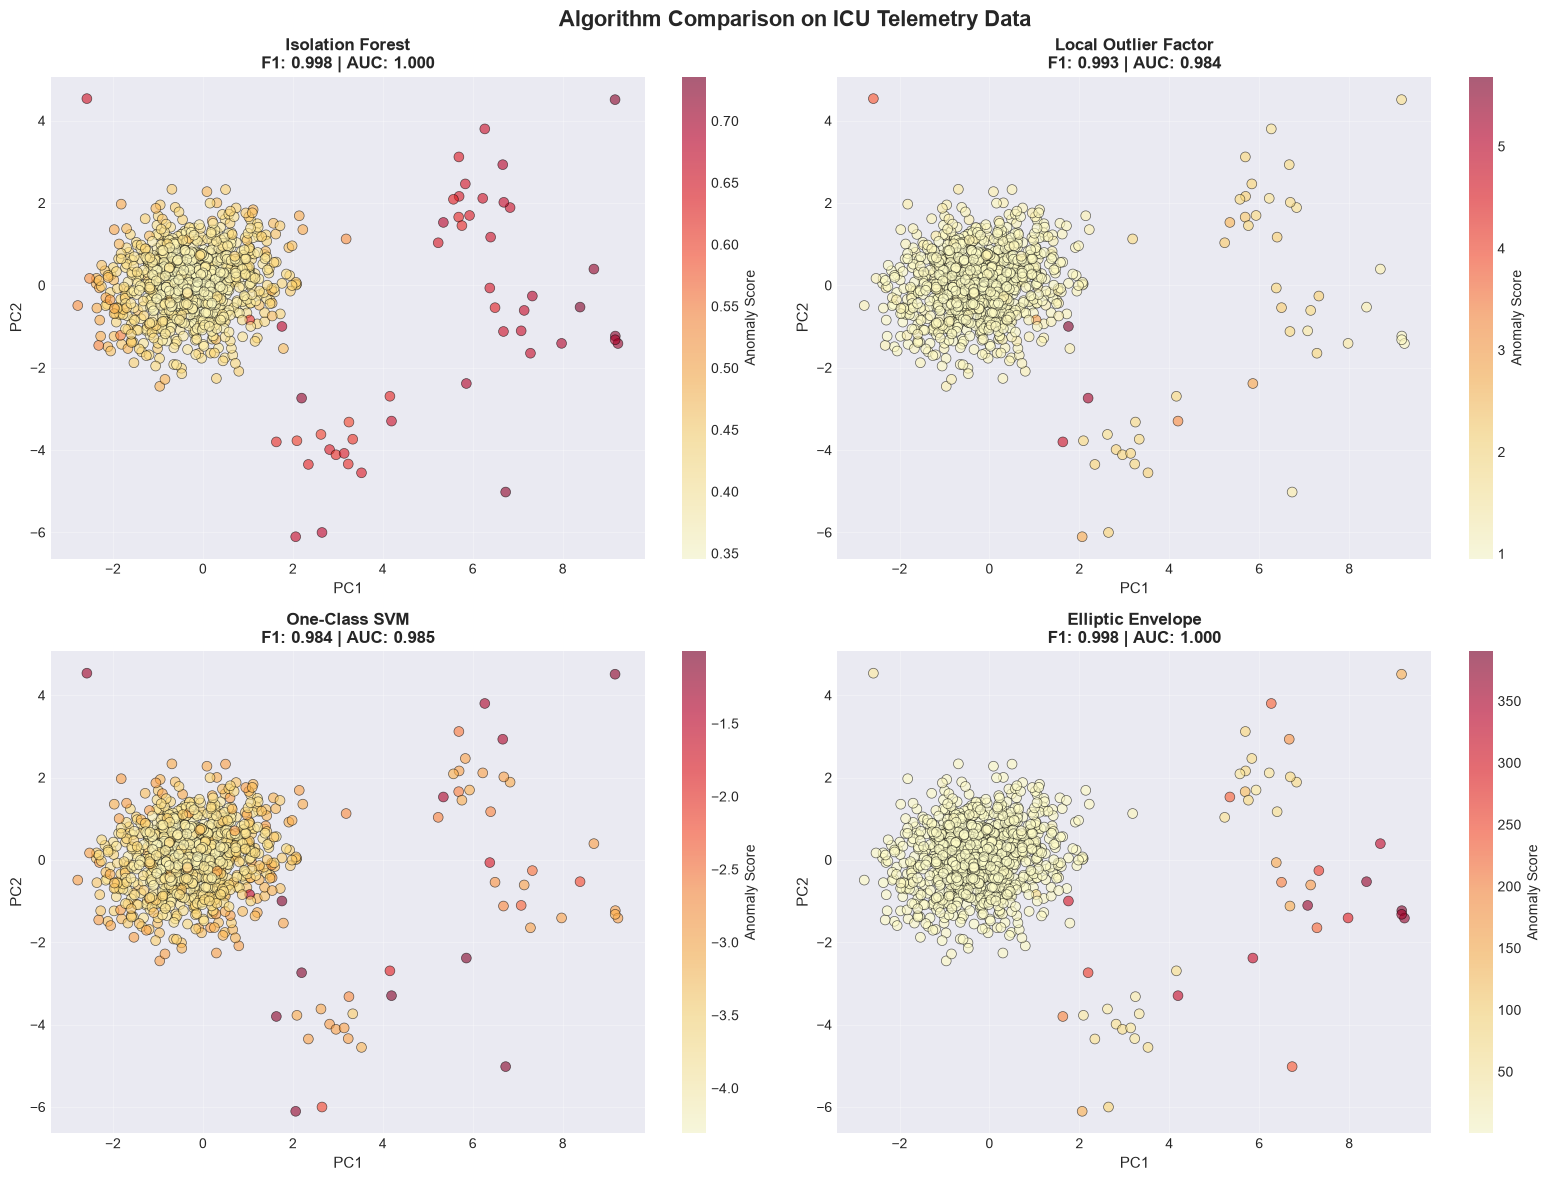

In [22]:
# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Algorithm Comparison on ICU Telemetry Data', fontsize=16, fontweight='bold')

for idx, (name, result) in enumerate(results.items()):
    ax = axes[idx // 2, idx % 2]
    
    # Plot predictions in PCA space
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                         c=-result['Scores'], cmap='YlOrRd',
                         alpha=0.6, s=50, edgecolors='k', linewidth=0.5)
    
    ax.set_xlabel('PC1', fontsize=11)
    ax.set_ylabel('PC2', fontsize=11)
    ax.set_title(f"{name}\nF1: {result['F1-Score']:.3f} | AUC: {result['ROC AUC']:.3f}", 
                 fontsize=12, fontweight='bold')
    plt.colorbar(scatter, ax=ax, label='Anomaly Score')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

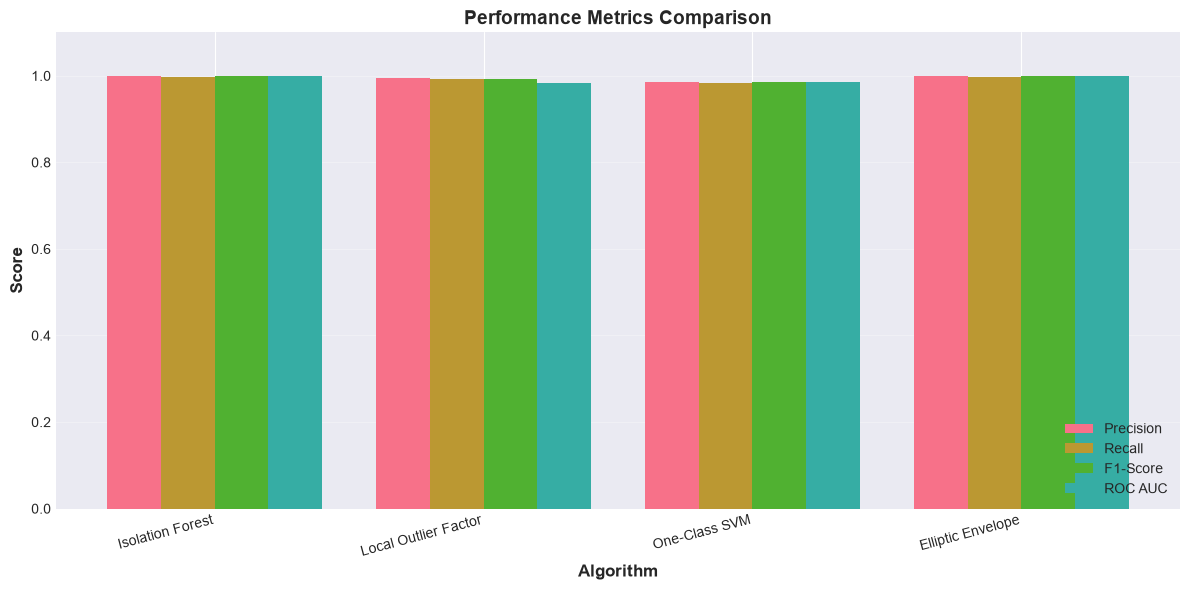

In [23]:
# Performance metrics comparison
metrics_to_plot = ['Precision', 'Recall', 'F1-Score', 'ROC AUC']
comparison_data = results_df[metrics_to_plot]

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(comparison_data.index))
width = 0.2

for i, metric in enumerate(metrics_to_plot):
    ax.bar(x + i * width, comparison_data[metric], width, label=metric)

ax.set_xlabel('Algorithm', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Performance Metrics Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(comparison_data.index, rotation=15, ha='right')
ax.legend(loc='lower right')
ax.grid(alpha=0.3, axis='y')
ax.set_ylim([0, 1.1])

plt.tight_layout()
plt.show()

## 9. Feature Importance Analysis

While Isolation Forest doesn't provide built-in feature importance, we can analyze which features contribute most to anomaly detection by examining the distribution of anomaly scores across features.

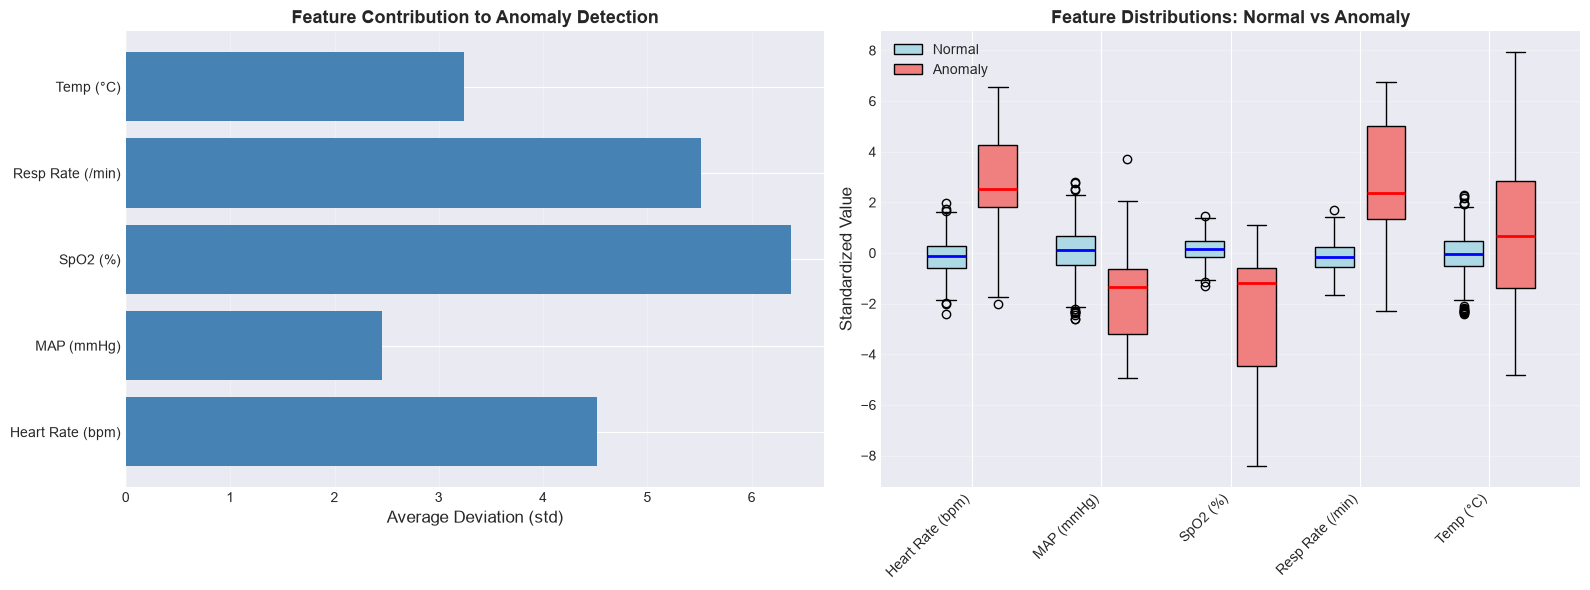


Feature Importance (by deviation):
  SpO2 (%)                 : 6.38 std
  Resp Rate (/min)         : 5.52 std
  Heart Rate (bpm)         : 4.52 std
  Temp (°C)                : 3.24 std
  MAP (mmHg)               : 2.46 std


In [24]:
# Analyze feature contributions for detected anomalies
anomaly_indices = np.where(y_pred == -1)[0]
normal_indices = np.where(y_pred == 1)[0]

# Calculate how much each feature deviates from normal for detected anomalies
feature_deviations = []

for i, feature in enumerate(feature_names):
    normal_mean = X_scaled[normal_indices, i].mean()
    normal_std = X_scaled[normal_indices, i].std()
    
    anomaly_values = X_scaled[anomaly_indices, i]
    avg_deviation = np.abs(anomaly_values - normal_mean).mean() / (normal_std + 1e-10)
    
    feature_deviations.append(avg_deviation)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar plot of feature deviations
axes[0].barh(feature_names, feature_deviations, color='steelblue')
axes[0].set_xlabel('Average Deviation (std)', fontsize=12)
axes[0].set_title('Feature Contribution to Anomaly Detection', fontsize=13, fontweight='bold')
axes[0].grid(alpha=0.3, axis='x')

# Box plots comparing distributions
positions = np.arange(len(feature_names))
bp_normal = axes[1].boxplot([X_scaled[normal_indices, i] for i in range(len(feature_names))],
                             positions=positions - 0.2, widths=0.3,
                             patch_artist=True, 
                             boxprops=dict(facecolor='lightblue'),
                             medianprops=dict(color='blue', linewidth=2),
                             label='Normal')

bp_anomaly = axes[1].boxplot([X_scaled[anomaly_indices, i] for i in range(len(feature_names))],
                              positions=positions + 0.2, widths=0.3,
                              patch_artist=True,
                              boxprops=dict(facecolor='lightcoral'),
                              medianprops=dict(color='red', linewidth=2),
                              label='Anomaly')

axes[1].set_xticks(positions)
axes[1].set_xticklabels(feature_names, rotation=45, ha='right')
axes[1].set_ylabel('Standardized Value', fontsize=12)
axes[1].set_title('Feature Distributions: Normal vs Anomaly', fontsize=13, fontweight='bold')
axes[1].legend([bp_normal['boxes'][0], bp_anomaly['boxes'][0]], ['Normal', 'Anomaly'])
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\nFeature Importance (by deviation):")
for feature, deviation in sorted(zip(feature_names, feature_deviations), 
                                 key=lambda x: x[1], reverse=True):
    print(f"  {feature:25s}: {deviation:.2f} std")

## 10. Examining Specific Anomalies

Let's look at the most anomalous samples to understand what makes them unusual.

TOP 10 MOST ANOMALOUS SAMPLES

Rank 1 - Sample #420
  Anomaly Score: -0.7358
  True Label: ANOMALY
  Predicted: ANOMALY

  Vital Signs:
    Heart Rate (bpm)         :   115.69
    MAP (mmHg)               :    99.24
    SpO2 (%)                 :    81.31
    Resp Rate (/min)         :    35.15
    Temp (°C)                :    36.74
----------------------------------------------------------------------------------------------------

Rank 2 - Sample #83
  Anomaly Score: -0.7310
  True Label: ANOMALY
  Predicted: ANOMALY

  Vital Signs:
    Heart Rate (bpm)         :   161.08
    MAP (mmHg)               :    74.30
    SpO2 (%)                 :    92.12
    Resp Rate (/min)         :    28.07
    Temp (°C)                :    39.56
----------------------------------------------------------------------------------------------------

Rank 3 - Sample #450
  Anomaly Score: -0.7277
  True Label: ANOMALY
  Predicted: ANOMALY

  Vital Signs:
    Heart Rate (bpm)         :   109.26
    MAP (mm

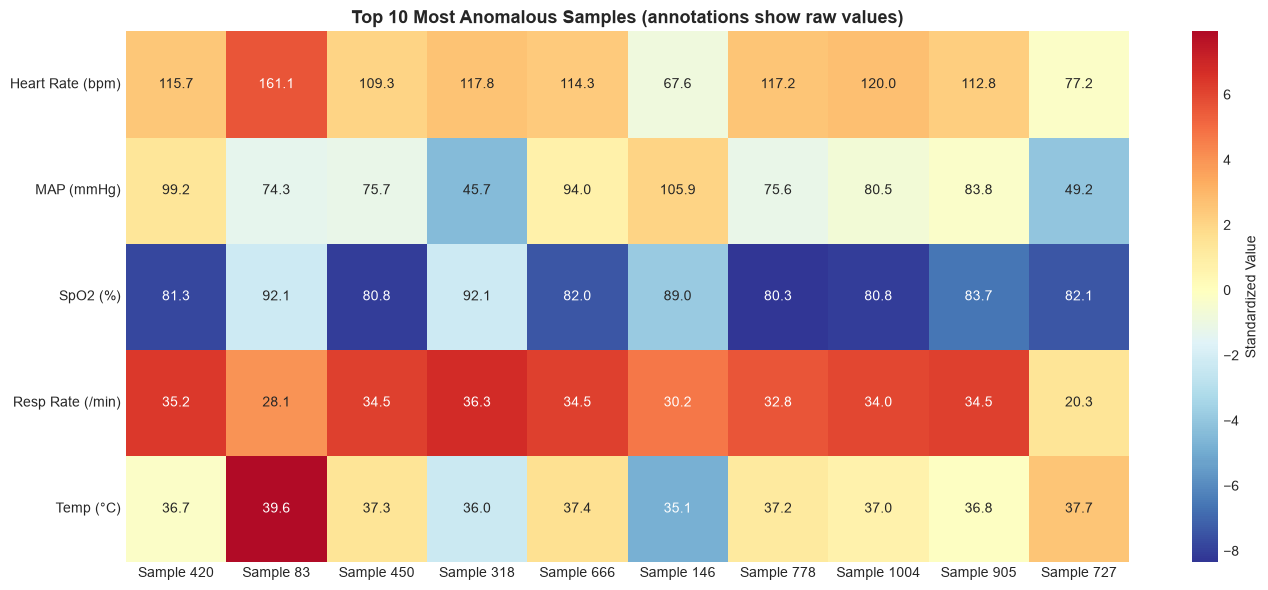

In [25]:
# Get top 10 most anomalous samples
most_anomalous_indices = np.argsort(anomaly_scores)[:10]

print("TOP 10 MOST ANOMALOUS SAMPLES")
print("="*100)

for rank, idx in enumerate(most_anomalous_indices, 1):
    print(f"\nRank {rank} - Sample #{idx}")
    print(f"  Anomaly Score: {anomaly_scores[idx]:.4f}")
    print(f"  True Label: {'ANOMALY' if y_true[idx] == -1 else 'Normal'}")
    print(f"  Predicted: {'ANOMALY' if y_pred[idx] == -1 else 'Normal'}")
    print("\n  Vital Signs:")
    for feature, value in zip(feature_names, X[idx]):
        print(f"    {feature:25s}: {value:8.2f}")
    print("-" * 100)

# Visualize these samples
fig, ax = plt.subplots(figsize=(14, 6))

# Heatmap of most anomalous samples
anomaly_data = X_scaled[most_anomalous_indices]
sns.heatmap(anomaly_data.T, annot=X[most_anomalous_indices].T, fmt='.1f',
            cmap='RdYlBu_r', center=0, 
            xticklabels=[f"Sample {i}" for i in most_anomalous_indices],
            yticklabels=feature_names,
            cbar_kws={'label': 'Standardized Value'},
            ax=ax)
ax.set_title('Top 10 Most Anomalous Samples (annotations show raw values)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 11. Key Takeaways and Best Practices

### When to Use Isolation Forest

✅ **Good for:**
- Large datasets (efficient)
- High-dimensional data
- Unknown anomaly types
- Real-time applications
- No assumptions about data distribution

❌ **Not ideal for:**
- Very small datasets (< 100 samples)
- When anomalies are clusters (not isolated points)
- When you need interpretable rules

### Hyperparameter Tuning Tips

1. **contamination**:
   - Start with domain knowledge estimate
   - Use validation set if available
   - Conservative values (lower) reduce false alarms

2. **n_estimators**:
   - 100-200 is usually sufficient
   - More trees = more stable, but diminishing returns

3. **max_samples**:
   - Default 'auto' (256) works well for most cases
   - Smaller values for very large datasets

4. **max_features**:
   - 1.0 (all features) is standard
   - Reduce for very high dimensions or redundant features

### Production Deployment Considerations

1. **Threshold Selection**: Use clinical expertise to set appropriate alarm thresholds
2. **Model Updates**: Retrain periodically as the "normal" case mix evolves
3. **Feature Scaling**: Always standardize features in production
4. **Monitoring**: Track false positive rates and adjust contamination - alarm fatigue is a real patient-safety risk
5. **Human-in-the-Loop**: Use model scores to prioritize clinical review, never to replace it

### Clinical Applications

- **Early Warning Systems**: Detect deterioration hours before an adverse event
- **Monitor Quality Control**: Identify artefacts, displaced leads and failed probes
- **Sepsis and Shock Screening**: Flag unusual hemodynamic patterns
- **Post-Operative Surveillance**: Detect deviations from an expected recovery trajectory
- **Population Health**: Identify outlier claims, dosing errors or coding mistakes


## 12. Exercises

Try these exercises to deepen your understanding:

1. **Parameter Sensitivity**: Use the interactive widget to find the optimal contamination parameter

2. **Custom Data**: Modify the data generation function to create different types of anomalies

3. **Real-time Detection**: Implement a sliding window approach for streaming data

4. **Feature Engineering**: Add derived features (e.g., ratios, differences) and see if detection improves

5. **Threshold Optimization**: Find the anomaly score threshold that maximizes F1-score

6. **Comparison**: Load a real dataset and compare all four outlier detection methods

In [26]:
# Exercise space - implement your experiments here!

# Example: Find optimal threshold
def find_optimal_threshold(y_true, scores):
    """
    Find the anomaly score threshold that maximizes F1-score.
    """
    thresholds = np.percentile(scores, np.arange(1, 100, 1))
    best_f1 = 0
    best_threshold = None
    
    for threshold in thresholds:
        y_pred_temp = np.where(scores < threshold, -1, 1)
        cm = confusion_matrix(y_true, y_pred_temp)
        tn, fp, fn, tp = cm.ravel()
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
    
    return best_threshold, best_f1

# Try it out!
optimal_threshold, optimal_f1 = find_optimal_threshold(y_true, anomaly_scores)
print(f"Optimal Threshold: {optimal_threshold:.4f}")
print(f"Best F1-Score: {optimal_f1:.3f}")
print(f"Model's Threshold: {iso_forest.offset_:.4f}")

Optimal Threshold: -0.5359
Best F1-Score: 0.998
Model's Threshold: -0.5359


## Summary

In this notebook, you learned:

✓ The theory and intuition behind Isolation Forest
✓ How to apply it to ICU telemetry anomaly detection
✓ The effect of hyperparameters on performance
✓ How to interpret and visualize anomaly scores
✓ Comparison with other outlier detection methods
✓ Best practices for production deployment

Isolation Forest is a powerful, efficient algorithm for anomaly detection that works well in many real-world scenarios, especially when dealing with high-dimensional data and unknown anomaly patterns.

---

**Next Steps:**
- Explore other ensemble methods
- Study deep learning approaches to anomaly detection
- Apply these techniques to your own datasets

**References:**
- Liu, F. T., Ting, K. M., & Zhou, Z. H. (2008). Isolation forest. ICDM.
- Scikit-learn documentation: https://scikit-learn.org/stable/modules/outlier_detection.html
